# clock/head_inspection — what is in each head set, and how was it chosen?

Six head sets are used across the project, each localized by a different method and each carrying a
different per-head score. This notebook loads all of them **from disk only** (no model weights —
`AutoConfig` supplies `n_layer`/`n_heads`), shows the score landscape, marks which heads the current
config selects, and exports the selections as json for `eval_goalscope.py --heads <path>.json`.

| set | score | source | selection rule |
|---|---|---|---|
| `goal` | learned mask value | `localization/<model>/<tag>/head_mask.pt` | `> threshold` inside `GOAL_BANDS` |
| `decision` | learned mask value | `multistep_clock/<ver>/<model>/completion_mask/<tag>/mask.pt` | `> threshold` |
| `gaze` | step-lookback ratio | `.../head_scores/qspan-<q>_cmp-<c>/aggregated.npz` | top-K |
| `fv` | causal indirect effect | `fv/<model>/aie_all_ns10_nt25.pt` | top-K |
| `concept-copier` | patched−corrupt on `m1` | dual-route `head_orderings/` or `causal_scores/` | top-K |
| `token-copier` | patched−corrupt on `m2` | same, `token_*` | top-K |

**Scores are not comparable across sets** — a mask value in [0,1] and an indirect effect in
probability units mean different things. Each panel is normalized independently; read *within* a
panel, not across.

Two caveats the summary table surfaces per set:
* **saturation** — the mask sets are trained with a sparsity penalty and clamp to [0,1], so many
  heads sit at exactly 1.0. If K falls inside that tie block the top-K is an arbitrary index-order
  cut, not a ranking. `n_tied@K` reports this.
* **degeneracy** — for copier sets read off a *partial* checkpoint the scores can be at noise level.
  Compare `score@1` with `score@K`; if they are both ~0 the selection is arbitrary.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, json, glob, logging
sys.path.append("../..")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from dataclasses import dataclass, field
from pathlib import Path
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from src.utils import logging_utils, env_utils

logging_utils.configure(level=logging.WARNING)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)
RES = env_utils.DEFAULT_RESULTS_DIR
RES

'/disk/u/arnab/Codes/Projects/goals/results'

In [2]:
# ── model geometry only: no weights are loaded, so this notebook needs no GPU ──
from transformers import AutoConfig

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
SLUG = MODEL_NAME.split("/")[-1]
_cfg = AutoConfig.from_pretrained(MODEL_NAME)
N_LAYER = _cfg.num_hidden_layers
N_HEADS = _cfg.num_attention_heads
print(f"{SLUG}: n_layer={N_LAYER}  n_heads={N_HEADS}  ({N_LAYER * N_HEADS} heads total)")

Qwen2.5-Coder-32B-Instruct: n_layer=64  n_heads=40  (2560 heads total)


In [3]:
# ── per-set config — edit here, everything downstream follows ────────────────
# TOPK is the selection rule for the score-ranked sets (gaze / fv / copiers); the two mask sets use
# a threshold instead. `None` for GAZE_TOPK means "match the goal-head count", which is what
# eval_goalscope does today.
# Every set takes `path` and `ckpt`:
#   path=None  -> derive the artifact path from the other knobs (tag / version / source)
#   path="..." -> use that file verbatim; every path-deriving knob is then ignored (and saying
#                 both is an error, so a run can never claim a `tag` it did not read)
#   ckpt=None  -> the final mask;  ckpt=<int> -> that epoch's checkpoint;  ckpt="name.pt" -> exact
# `resolve_artifact()` below prints what it opened, so a selection is always traceable to a file.
CFG = dict(
    # goal / decision: give EXACTLY ONE of `threshold` or `topk`; both or neither is an error.
    # `topk` ranks by mask value over the WHOLE mask and deliberately ignores the layer band, so
    # `band` must stay None in that mode (matching the --top-k semantics agreed for eval_goalscope).
    # goal      = dict(tag="lam20", threshold=0.9, topk=None, band=None),  #* band=None with threshold!=None -> GOAL_BANDS
    goal      = dict(tag="lam20", threshold=None, topk=150, band=None, path=None, ckpt=None),
    decision  = dict(version="conditions", tag="lam10.0", threshold=0.8, topk=None, path=None, ckpt=None),
    gaze      = dict(version="conditions", q_span=15, compare="mean", topk=None, path=None),  # None -> match goal
    fv        = dict(source="cma", topk=150, mask_lam="1", mask_threshold=0.5, path=None, ckpt=None),
    concept   = dict(topk=150, allow_partial=True, path=None),
    token     = dict(topk=150, allow_partial=True, path=None),
)

def resolve_artifact(c, derived, ckpt_dir=None, ckpt_fmt=None, what="artifact"):
    """The file a loader should open, and a provenance string naming it.

    `derived` is the path implied by the config's other knobs. An explicit `c["path"]` wins
    outright. `c["ckpt"]` picks a per-epoch checkpoint instead of the final mask: an int is
    formatted with `ckpt_fmt` inside `ckpt_dir`, a string is used as a filename there.

    Returns (path, provenance_suffix). Raises if the file is absent, with the directory listing —
    a wrong tag is otherwise a bare FileNotFoundError with no hint about what IS available."""
    if c.get("path"):
        p = os.path.expanduser(str(c["path"]))
        if not os.path.exists(p):
            raise FileNotFoundError(f"{what}: --path {p} does not exist")
        return p, f"path={p}"
    p, prov = derived, ""
    if c.get("ckpt") is not None:
        if ckpt_dir is None:
            raise ValueError(f"{what}: this set has no per-epoch checkpoints; drop `ckpt`")
        fn = ckpt_fmt.format(int(c["ckpt"])) if isinstance(c["ckpt"], int) else str(c["ckpt"])
        p = os.path.join(ckpt_dir, fn)
        prov = f" ckpt={fn}"
        if not os.path.exists(p):
            avail = sorted(os.listdir(ckpt_dir)) if os.path.isdir(ckpt_dir) else []
            raise FileNotFoundError(
                f"{what}: no checkpoint {fn!r} in {ckpt_dir}. available: {avail[:8]}"
                f"{' …' if len(avail) > 8 else ''}")
    if not os.path.exists(p):
        d = os.path.dirname(p)
        avail = sorted(os.listdir(d)) if os.path.isdir(d) else []
        raise FileNotFoundError(f"{what}: {p} not found. available in {d}: {avail[:10]}"
                                f"{' …' if len(avail) > 10 else ''}")
    return p, prov


def validate_cfg(name, c):
    """Check ONE config dict and return it. Raises on anything readable two ways.

    Takes the config as an argument rather than reading CFG, so an ad-hoc config passed to a loader
    (e.g. a sparsity sweep point) gets exactly the same checks as the module-level default. A
    silently-ignored knob is the failure mode that matters: these selections are exported to json
    and consumed by eval_goalscope, so a config that *looks* like it filtered one way while
    selecting another would propagate into run dirs with nothing downstream able to notice."""
    if name in ("goal", "decision"):
        thr, k = c.get("threshold"), c.get("topk")
        if (thr is None) == (k is None):
            raise ValueError(
                f"{name}: set exactly one of `threshold` or `topk` — got threshold={thr!r}, "
                f"topk={k!r}. They are different selection rules and combining them would "
                f"silently apply only one."
            )
        if k is not None:
            if not (isinstance(k, int) and k > 0):
                raise ValueError(f"{name}['topk'] must be a positive int, got {k!r}")
            if name == "goal" and c.get("band") is not None:
                raise ValueError(
                    "goal: `topk` ranks over the whole mask and ignores the layer band, so `band` "
                    "must be None when `topk` is set. Use `threshold` if you want the band."
                )
    if name == "fv":
        if c.get("source") not in ("cma", "mask"):
            raise ValueError(f"fv['source'] must be 'cma' or 'mask', got {c.get('source')!r}")
        if c["source"] == "cma" and c.get("topk") is None:
            raise ValueError("fv: source='cma' ranks by AIE and needs a `topk`")
    if name in ("concept", "token") and c.get("topk") is None:
        raise ValueError(f"{name}: `topk` is the only selection rule for this set")
    k = c.get("topk")
    if k is not None and not (isinstance(k, int) and k > 0):
        raise ValueError(f"{name}['topk'] must be a positive int, got {k!r}")
    # An explicit `path` supersedes every path-deriving knob, so saying both is ambiguous: the run
    # would record a tag/source it never actually read.
    if c.get("path"):
        clash = [j for j in ("tag", "version", "source", "mask_lam", "ckpt") if c.get(j) is not None]
        if clash:
            raise ValueError(
                f"{name}: `path` supersedes path-derivation, so it cannot be combined with "
                f"{clash}. Drop those, or drop `path`."
            )
    return c


def _validate_all():
    for name in CFG:
        validate_cfg(name, CFG[name])


_validate_all()
DR_ROOT = "../../existing_works/dual-route-induction"

@dataclass
class HeadSet:
    name: str
    grid: np.ndarray                  # (n_layer, n_heads); NaN where the method scored nothing
    selected: list                    # [(layer, head), ...]
    score_label: str
    provenance: str
    cfg: dict = field(default_factory=dict)
    higher_is_better: bool = True

    @property
    def key(self): return set(map(tuple, self.selected))

def _blank():  # NaN = "this method produced no score here", drawn in grey, never ranked
    return np.full((N_LAYER, N_HEADS), np.nan, dtype=float)

def _place(layers, values):
    g = _blank()
    for li, L in enumerate(layers):
        g[int(L)] = values[li]
    return g

def _topk(grid, k):
    """Top-k by score over the non-NaN entries, ties broken by ASCENDING (layer, head) index.

    Sorting the negated array stably (rather than sorting ascending and reversing) matters when the
    cut runs through a tie block: reversing would resolve ties highest-index-first and skew the
    selection toward deep layers / high head indices. The mask sets saturate at exactly 1.0, so this
    is a live case for them — `n_tied@K` in the summary table flags when it is happening."""
    flat = np.where(np.isnan(grid), -np.inf, grid).ravel()
    order = np.argsort(-flat, kind="stable")[:k]
    return [(int(i // N_HEADS), int(i % N_HEADS)) for i in order]

In [4]:
# ── loaders: one per head set, each returns the full score grid + the selection ──
# Every loader takes `cfg=None` -> falls back to CFG[name]. Passing a dict lets one loader
# serve any config (a sparsity sweep point, a different tag) without mutating global state.
# Only the per-model layer-band registry is borrowed; selection is done here so that any config
# can be expressed, including ones eval_goalscope has no flag for.
from scripts.evaluation.eval_goalscope import default_goal_band
from scripts.clock.score_condition_heads import load_head_scores
from src.goals.oid_gaze import cache_root

def load_goal(cfg=None):
    c = validate_cfg("goal", cfg or CFG["goal"])
    root = os.path.join(RES, "localization", SLUG, str(c.get("tag") or ""))
    p, prov = resolve_artifact(c, os.path.join(root, "head_mask.pt"),
                               ckpt_dir=os.path.join(root, "checkpoints"),
                               ckpt_fmt="checkpoint_epoch_{:04d}.pt", what="goal mask")
    ck = torch.load(p, map_location="cpu")
    grid = _place([int(x) for x in ck["layers"]], ck["mask_values"].numpy())
    if c["topk"] is not None:                      # global rank over the mask; band ignored by design
        return HeadSet("goal", grid, _topk(grid, c["topk"]), "mask value",
                       f"{c.get('tag') or ''}{prov} top-{c['topk']} (global, band ignored)".lstrip(), dict(c, band=None))
    band = tuple(c["band"]) if c["band"] else default_goal_band(MODEL_NAME, n_layer=N_LAYER)
    m = np.nan_to_num(grid, nan=0.0).copy()
    m[: band[0]] = 0; m[band[1]:] = 0
    sel = [(int(l), int(h)) for l, h in np.argwhere(m > c["threshold"])]
    return HeadSet("goal", grid, sel, "mask value", f"{c.get('tag') or ''}{prov} @>{c['threshold']} band {band[0]}-{band[1]}".lstrip(),
                   dict(c, band=list(band)))

def load_decision(cfg=None):
    c = validate_cfg("decision", cfg or CFG["decision"])
    if c.get("path"):
        p, prov = resolve_artifact(c, None, what="decision mask")
        latest = os.path.basename(os.path.dirname(p))
    else:
        root = os.path.join(cache_root(MODEL_NAME, c["version"]), "completion_mask")
        dirs = [t for t in os.listdir(root) if os.path.isdir(os.path.join(root, t))]
        # exact dir name wins; otherwise substring, but AMBIGUITY IS AN ERROR. The old code took
        # the newest by mtime, which silently picked a different lambda when tags overlapped
        # (e.g. "lam1" also matches lam10.0/lam100.0).
        if c["tag"] in dirs:
            latest = c["tag"]
        else:
            cands = [t for t in dirs if c["tag"] in t]
            if not cands:
                raise FileNotFoundError(f"no completion_mask dir matching {c['tag']!r} under "
                                        f"{root}. available: {sorted(dirs)}")
            if len(cands) > 1:
                raise ValueError(f"decision tag {c['tag']!r} matches {sorted(cands)} — give the "
                                 f"exact dir name (or a `path`).")
            latest = cands[0]
        p, prov = resolve_artifact(c, os.path.join(root, latest, "mask.pt"),
                                   ckpt_dir=os.path.join(root, latest, "epochs"),
                                   ckpt_fmt="mask_epoch{:02d}.pt", what="decision mask")
    ck = torch.load(p, map_location="cpu", weights_only=False)
    grid = _place([int(x) for x in ck["layers"]], ck["mask_values"].numpy())
    if c["topk"] is not None:
        return HeadSet("decision", grid, _topk(grid, c["topk"]), "mask value",
                       f"{latest}{prov} top-{c['topk']}", c)
    sel = [(int(l), int(h)) for l, h in np.argwhere(np.nan_to_num(grid, nan=0.0) > c["threshold"])]
    return HeadSet("decision", grid, sel, "mask value", f"{latest}{prov} @>{c['threshold']}", c)

def load_gaze(cfg=None):
    c = validate_cfg("gaze", cfg or CFG["gaze"])
    grid = load_head_scores(model=MODEL_NAME, version=c["version"],
                            q_span=c["q_span"], compare_with=c["compare"])["combined"].astype(float)
    # equal-N fallback deliberately uses the MODULE-level goal config, not a
    # sweep point: "match the goal-head count" means the default selection.
    k = c["topk"] if c["topk"] is not None else len(load_goal(CFG["goal"]).selected)
    return HeadSet("gaze", grid, _topk(grid, k), "lookback ratio",
                   f"qspan-{c['q_span']}_cmp-{c['compare']} top-{k}", dict(c, topk=k))

def load_fv(cfg=None):
    c = validate_cfg("fv", cfg or CFG["fv"])
    if c["source"] == "cma":
        p, prov = resolve_artifact(c, os.path.join(RES, "fv", SLUG, "aie_all_ns10_nt25.pt"),
                                   what="fv AIE")
        grid = torch.load(p, map_location="cpu", weights_only=False)["aie"].numpy().astype(float)
        return HeadSet("fv", grid, _topk(grid, c["topk"]), "AIE",
                       f"CMA {os.path.basename(p)}{prov} top-{c['topk']}", c)
    mdir = os.path.join(RES, "fv", SLUG, "head_mask", f"all_lam{c['mask_lam']}")
    p, prov = resolve_artifact(c, os.path.join(mdir, "mask.pt"), ckpt_dir=mdir,
                               ckpt_fmt="checkpoint_epoch_{:04d}.pt", what="fv joint mask")
    ck = torch.load(p, map_location="cpu", weights_only=False)
    grid = _place([int(x) for x in ck["layers"]], ck["mask_values"].numpy())
    sel = [(int(l), int(h)) for l, h in np.argwhere(np.nan_to_num(grid, nan=0.0) > c["mask_threshold"])]
    return HeadSet("fv", grid, sel, "mask value",
                   f"joint mask all_lam{c['mask_lam']}{prov} @>{c['mask_threshold']}", c)

def _load_copier(kind, cfg=None):
    """dual-route copier heads. The final ordering JSON carries a RANK only (no scores), so when it
    is present the grid holds -rank and the colourbar is a rank, not an effect size. The partial
    checkpoint does carry scores — but for a run that has not finished they can sit at noise level,
    which the summary table exposes via score@1 vs score@K.

    concept = patched.m1 - corrupt.m1 ; token = patched.m2 - corrupt.m2  (per convert_causal_scores.py,
    which is canonical — causal_scores.py's own inline json uses m1 for both)."""
    c = validate_cfg(kind, cfg or CFG[kind])
    j = c["path"] if (c.get("path") or "").endswith(".json") else \
        f"{DR_ROOT}/cache/head_orderings/{SLUG}/{kind}_copying.json"
    if os.path.exists(j):
        ranked = [tuple(int(v) for v in x) for x in json.load(open(j))]
        grid = _blank()
        n_tot = N_LAYER * N_HEADS
        for r, (l, h) in enumerate(ranked):
            grid[l, h] = 1.0 - r / max(1, n_tot - 1)   # percentile, 1 = top-ranked, ~0 = bottom
        return HeadSet(f"{kind}-copier", grid, ranked[: c["topk"]], "rank percentile",
                       f"{kind}_copying.json (final, ordering carries no scores) top-{c['topk']}", c)
    ckp = c["path"] if (c.get("path") or "").endswith(".pt") else \
        f"{DR_ROOT}/cache/causal_scores/{SLUG}/{kind}_len30_n1024.ckpt.pt"
    if not os.path.exists(ckp):
        raise FileNotFoundError(f"neither {j} nor {ckp} exists for {SLUG}")
    if not c["allow_partial"]:
        raise RuntimeError(f"only a PARTIAL checkpoint exists for {kind} on {SLUG}; "
                           f"set allow_partial=True in CFG to rank from it anyway")
    blob = torch.load(ckp, map_location="cpu", weights_only=False)
    fld = "m1_prob" if kind == "concept" else "m2_prob"
    corrupt, patched = blob["corrupt"], blob["patched"]
    diff = (patched[fld] / patched["n"] - corrupt[fld] / corrupt["n"]).numpy().reshape(N_LAYER, N_HEADS)
    prov = (f"PARTIAL checkpoint [{fld}] — {blob['done_batches']} batches / {corrupt['n']} examples "
            f"top-{c['topk']}")
    return HeadSet(f"{kind}-copier", diff.astype(float), _topk(diff, c["topk"]), f"Δp ({fld})", prov, c)

LOADERS = {"goal": load_goal, "decision": load_decision, "gaze": load_gaze, "fv": load_fv,
           "concept-copier": lambda cfg=None: _load_copier("concept", cfg),
           "token-copier": lambda cfg=None: _load_copier("token", cfg)}
# CFG key for a set name (the copiers are keyed without the "-copier" suffix)
CFG_KEY = {"concept-copier": "concept", "token-copier": "token"}

def load_set(name, cfg=None):
    """Load one head set by name, optionally with an ad-hoc config."""
    return LOADERS[name](cfg)

In [5]:
# ── load every head set under the current CFG ──
SETS = {}
for name, fn in LOADERS.items():
    try:
        SETS[name] = fn()
    except Exception as e:
        rich_print(f"[red]{name}: {type(e).__name__}: {e}[/red]")

t = Table(title=f"head sets · {SLUG}")
for c_, j in [("set", "left"), ("n", "right"), ("layers", "right"), ("score", "left"),
              ("score@1", "right"), ("score@K", "right"), ("n_tied@K", "right"), ("provenance", "left")]:
    t.add_column(c_, justify=j, overflow="fold")
for name, hs in SETS.items():
    g = hs.grid
    vals = np.sort(g[~np.isnan(g)])[::-1]
    k = len(hs.selected)
    at_k = vals[k - 1] if 0 < k <= len(vals) else np.nan
    tied = int((vals == at_k).sum()) if np.isfinite(at_k) else 0
    ls = sorted({l for l, _ in hs.selected})
    t.add_row(name, str(k), f"{ls[0]}-{ls[-1]}" if ls else "—", hs.score_label,
              f"{vals[0]:.4g}", f"{at_k:.4g}", str(tied) + (" ⚠" if tied > 1 else ""), hs.provenance)
rich_print(t)
rich_print("[grey58]n_tied@K > 1 means the K-th score is not unique — the cut runs through a tie "
           "block and which heads land inside is index order, not ranking.[/grey58]")

                                      head sets · Qwen2.5-Coder-32B-Instruct                                       
┏━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ set            ┃   n ┃ layers ┃ score          ┃   score@1 ┃   score@K ┃ n_tied@K ┃ provenance                  ┃
┡━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ goal           │ 150 │  23-63 │ mask value     │         1 │      0.75 │        1 │ lam20 top-150 (global, band │
│                │     │        │                │           │           │          │ ignored)                    │
│ decision       │ 181 │  11-62 │ mask value     │         1 │     0.806 │        1 │ diff_pt-2_both_L0-64_lam10. │
│                │     │        │                │           │           │          │ 0_n600 @>0.8                │
│ gaze           │ 150 │   8-61 │ lookback ratio │     3.478 │     2.579 │        1 │ qspan-15_cmp-mean top-150   │
│ fv             │ 150 │   0-63 │ AIE            │   0.05035 │ 0.0007744 │        1 │ CMA aie_all_ns10_nt25.pt    │
│                │     │        │                │           │           │          │ top-150                     │
│ concept-copier │ 150 │   5-62 │ Δp (m1_prob)   │ 0.0005444 │ 1.809e-05 │        1 │ PARTIAL checkpoint  — 25    │
│                │     │        │                │           │           │          │ batches / 800 examples      │
│                │     │        │                │           │           │          │ top-150                     │
│ token-copier   │ 150 │   3-63 │ Δp (m2_prob)   │  0.002363 │ 1.804e-05 │        1 │ PARTIAL checkpoint  — 25    │
│                │     │        │                │           │           │          │ batches / 800 examples      │
│                │     │        │                │           │           │          │ top-150                     │
└────────────────┴─────┴────────┴────────────────┴───────────┴───────────┴──────────┴─────────────────────────────┘

n_tied@K > 1 means the K-th score is not unique — the cut runs through a tie block and which heads land inside is 
index order, not ranking.

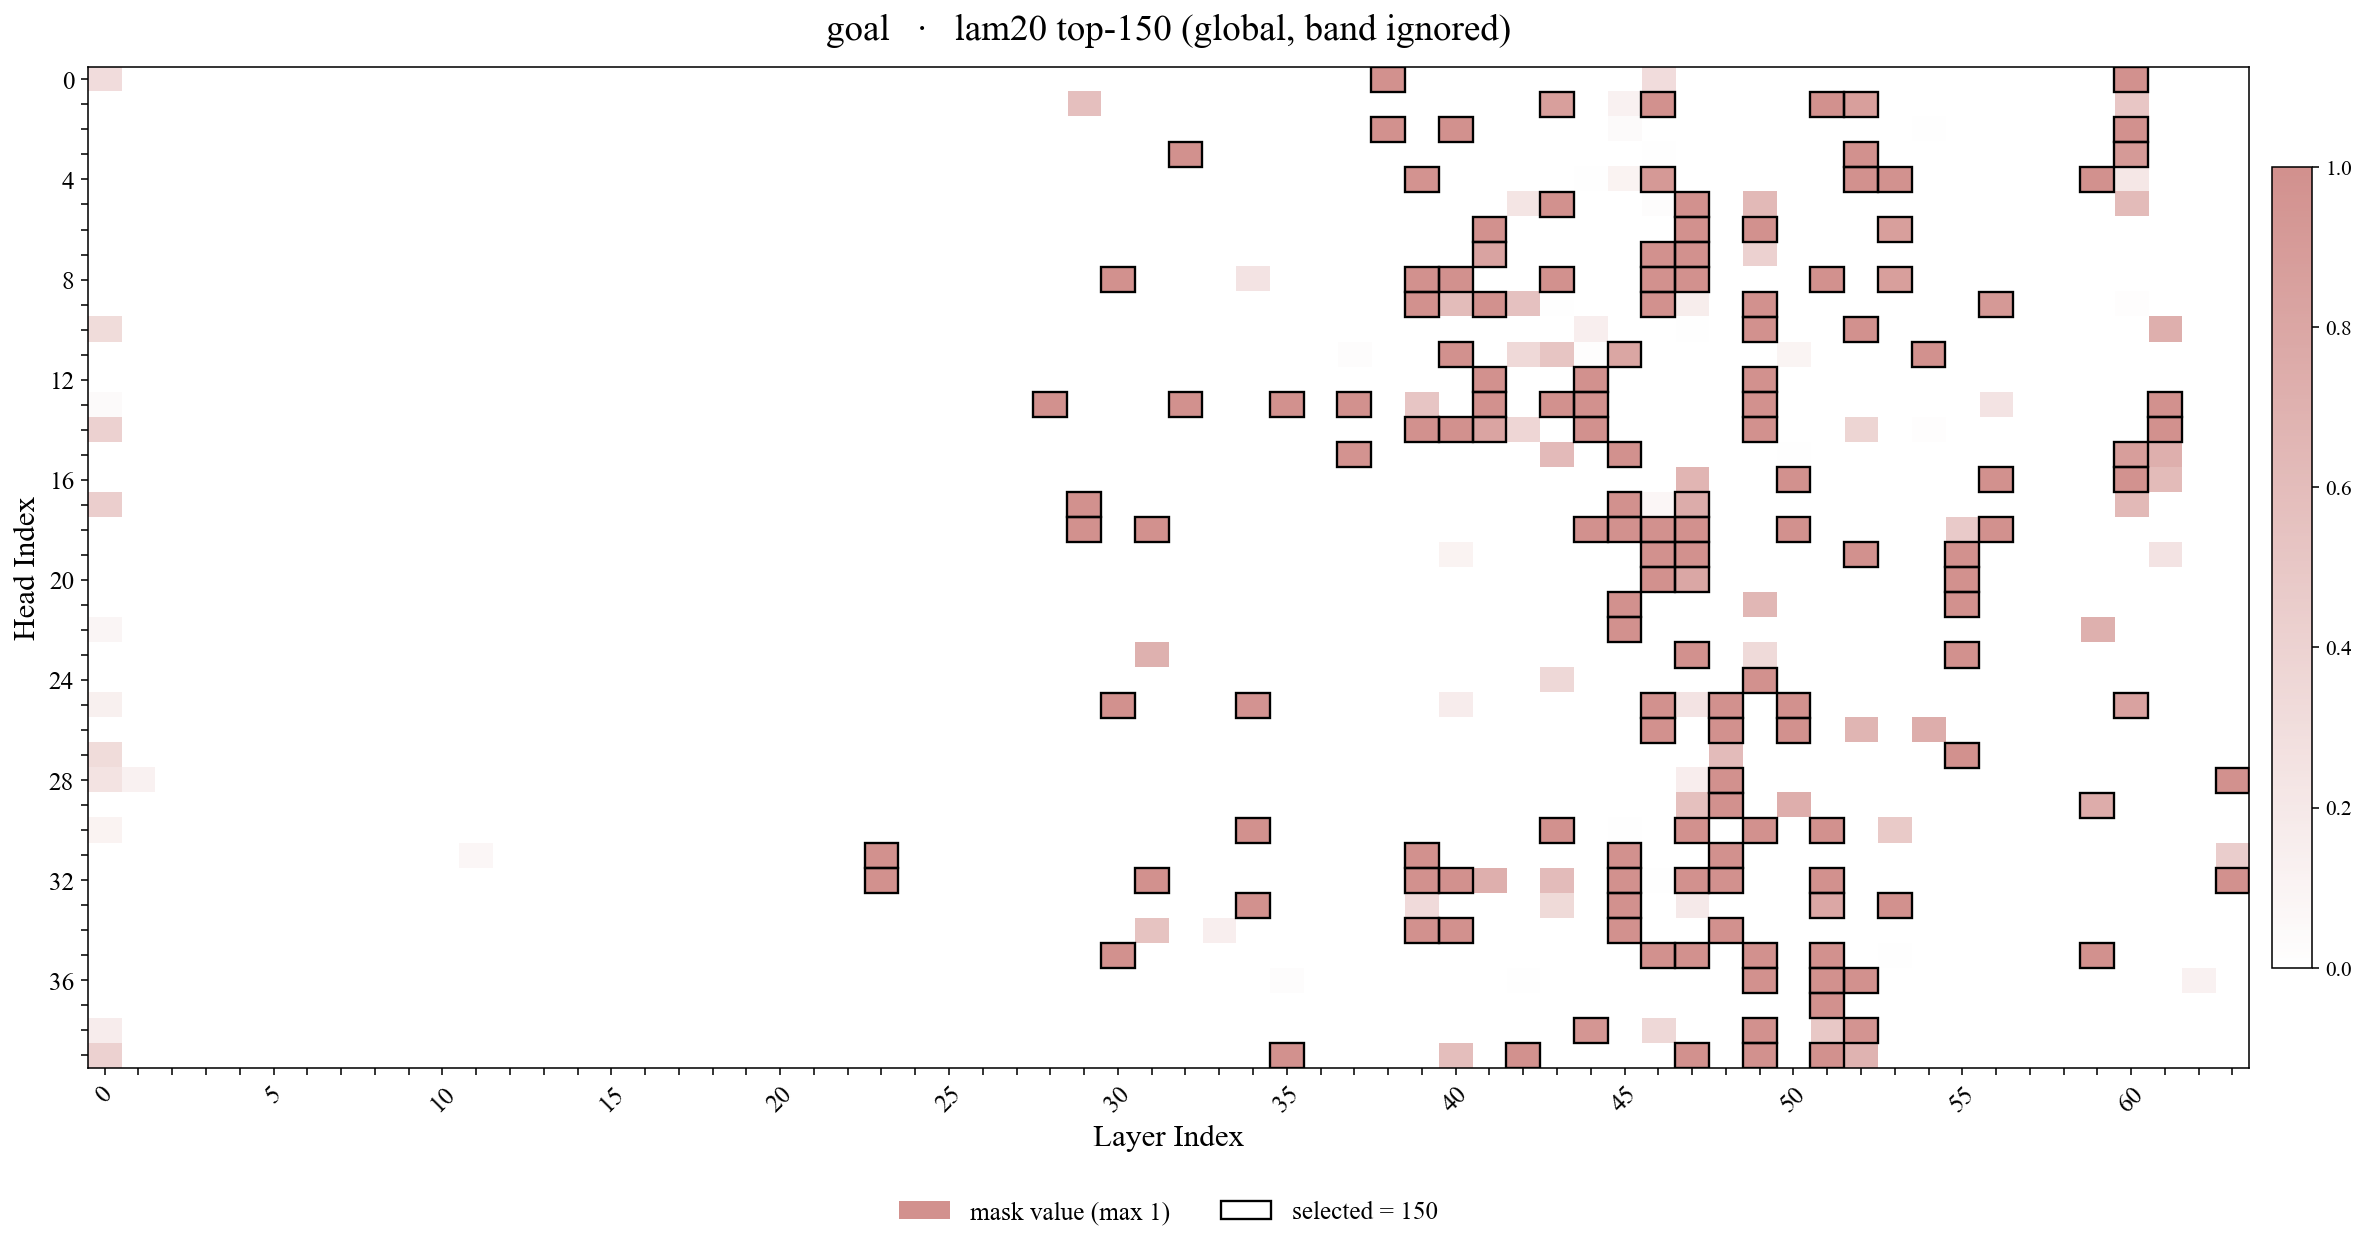

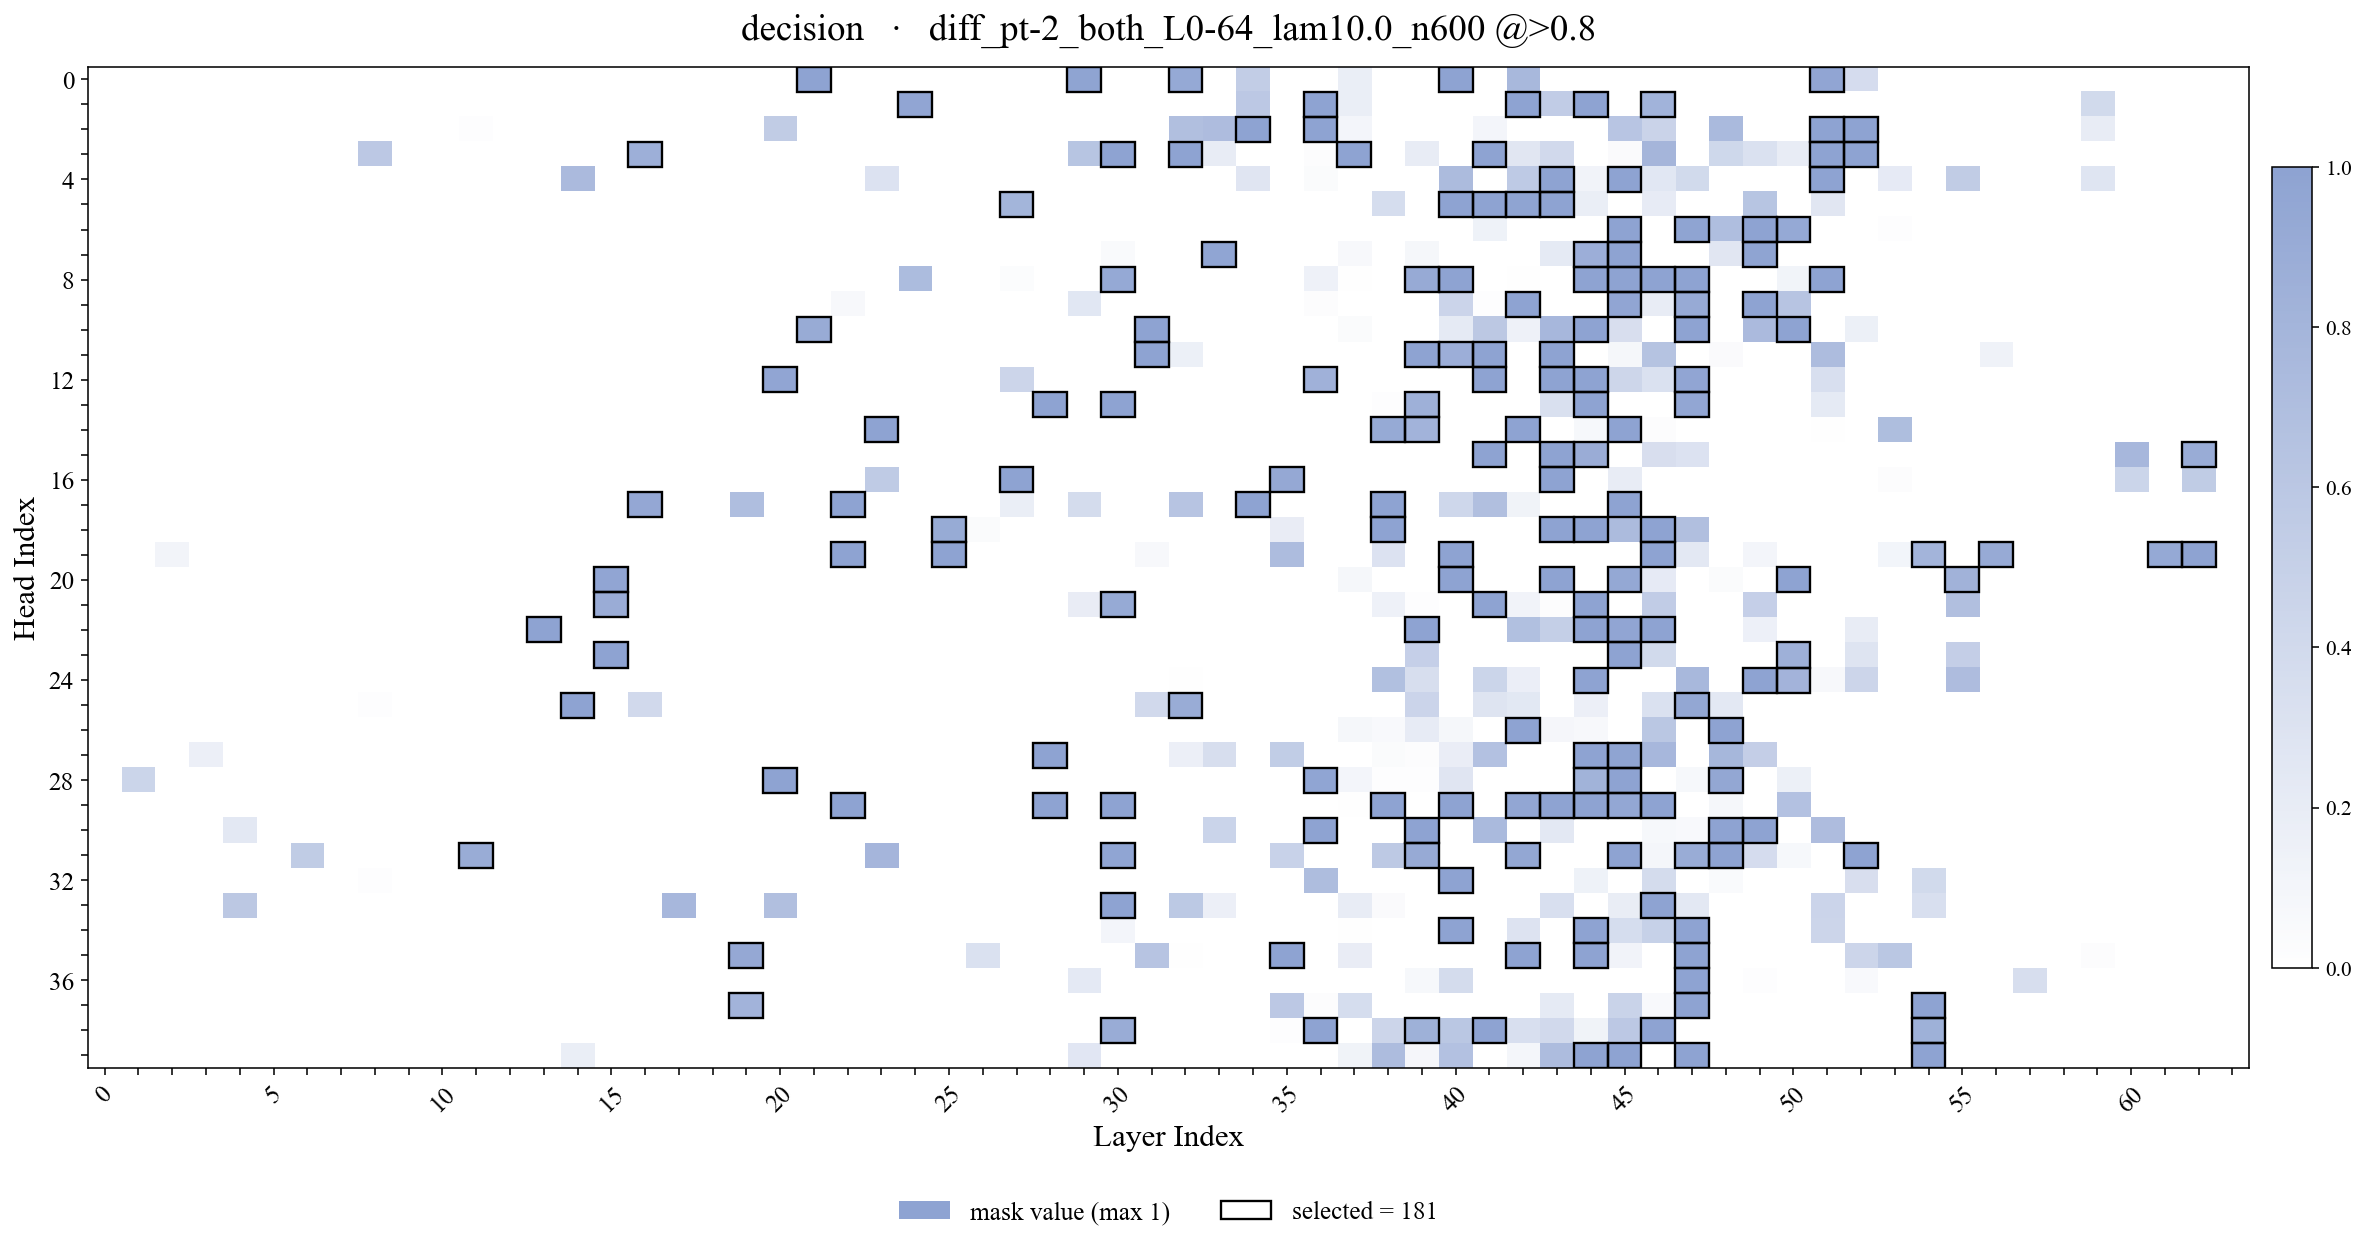

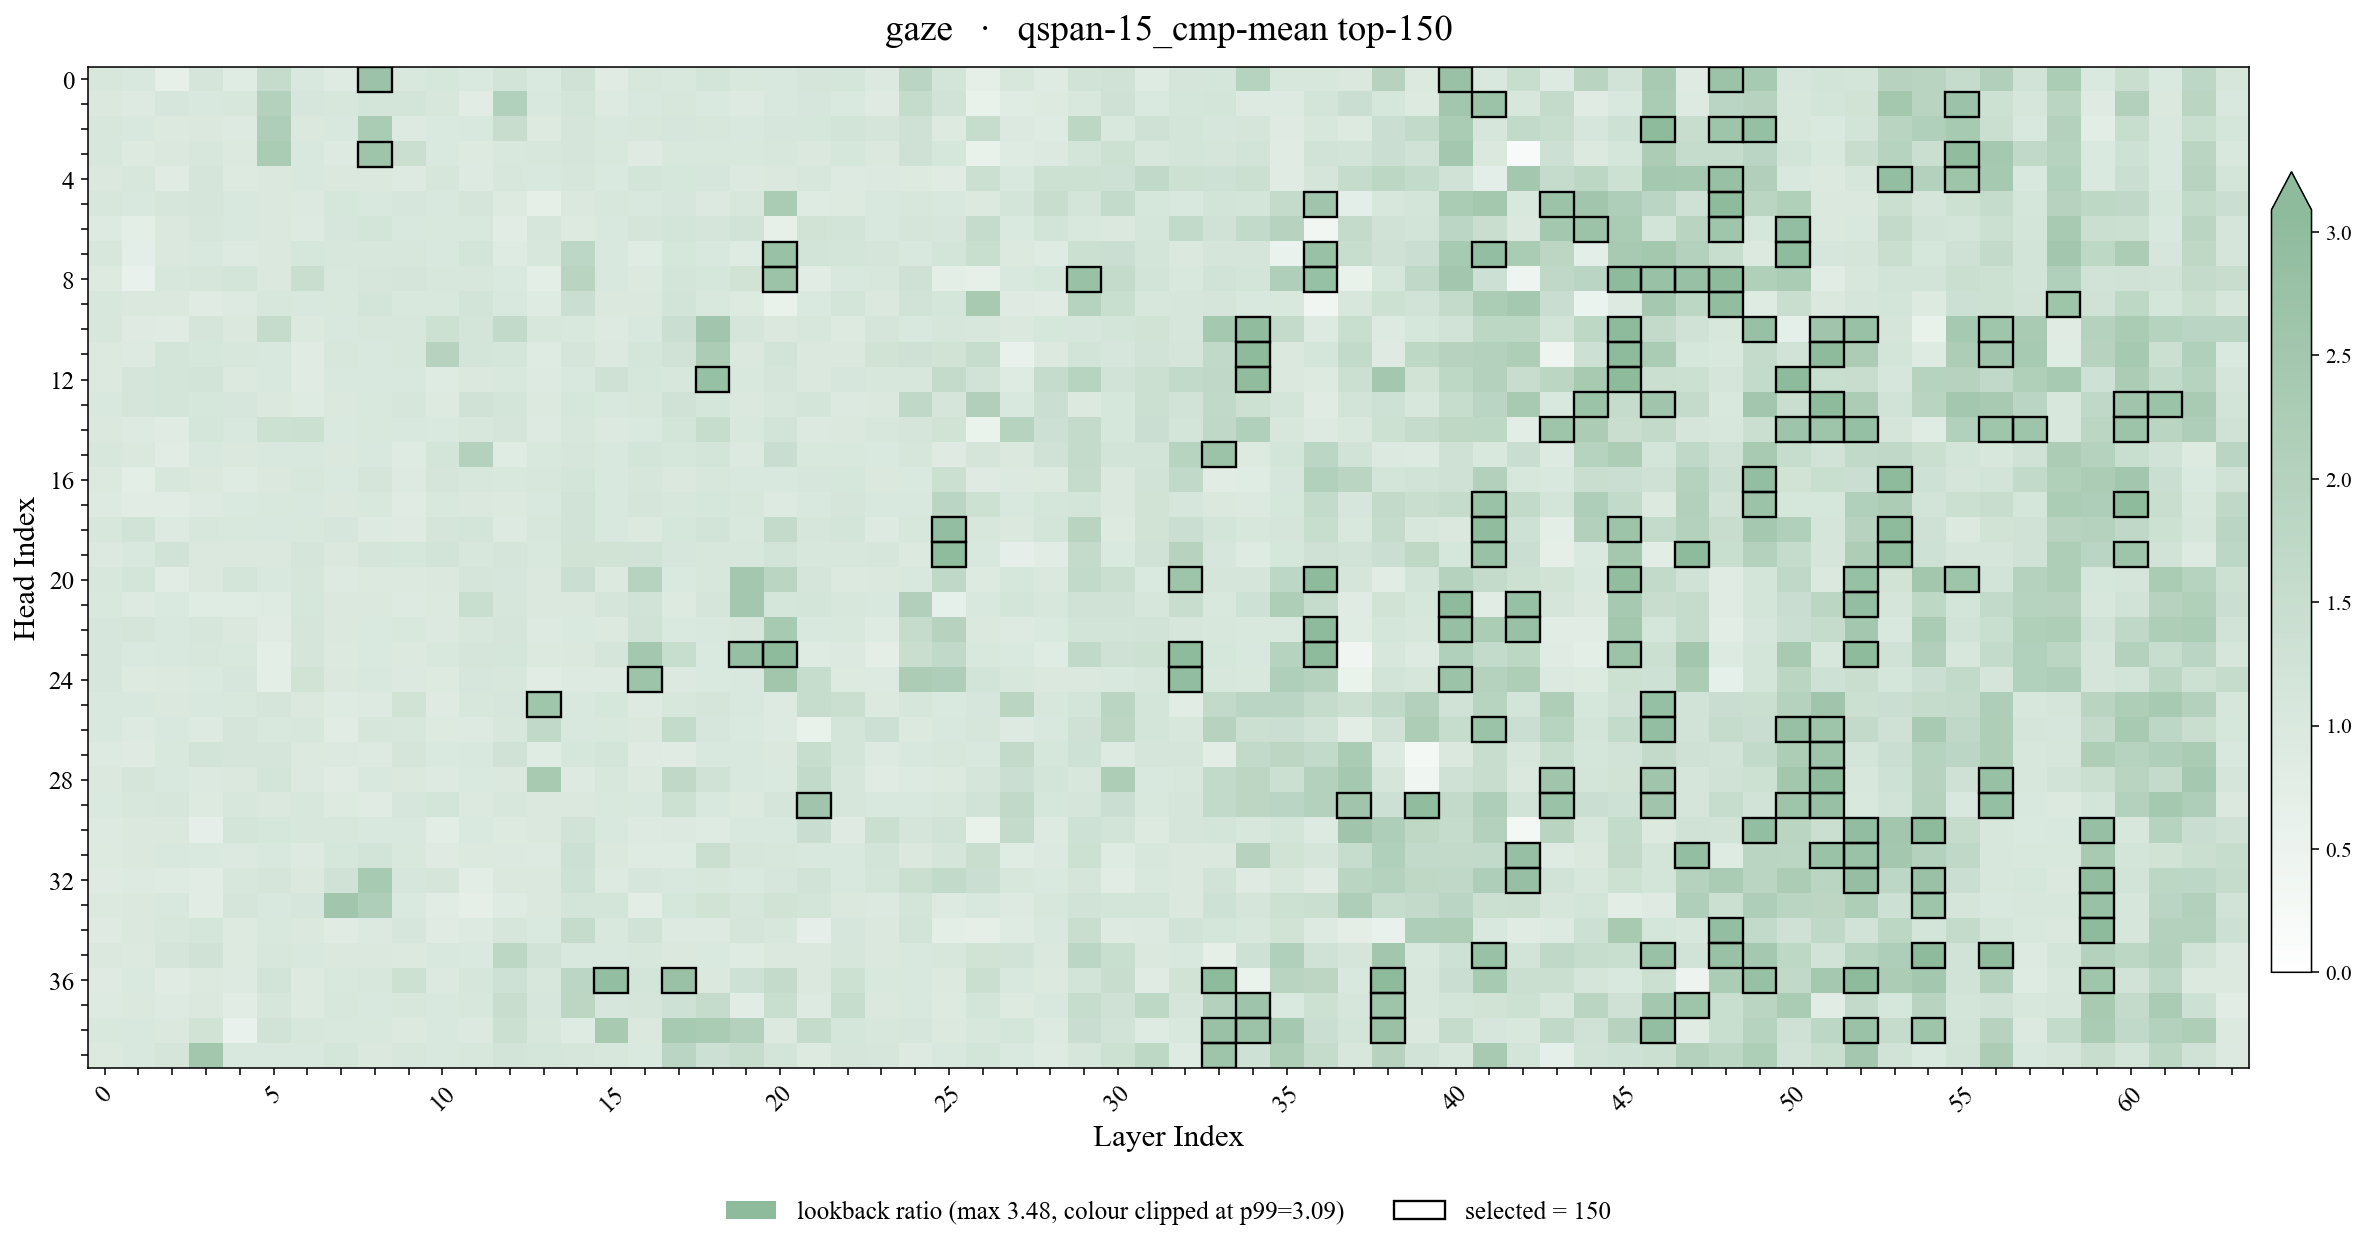

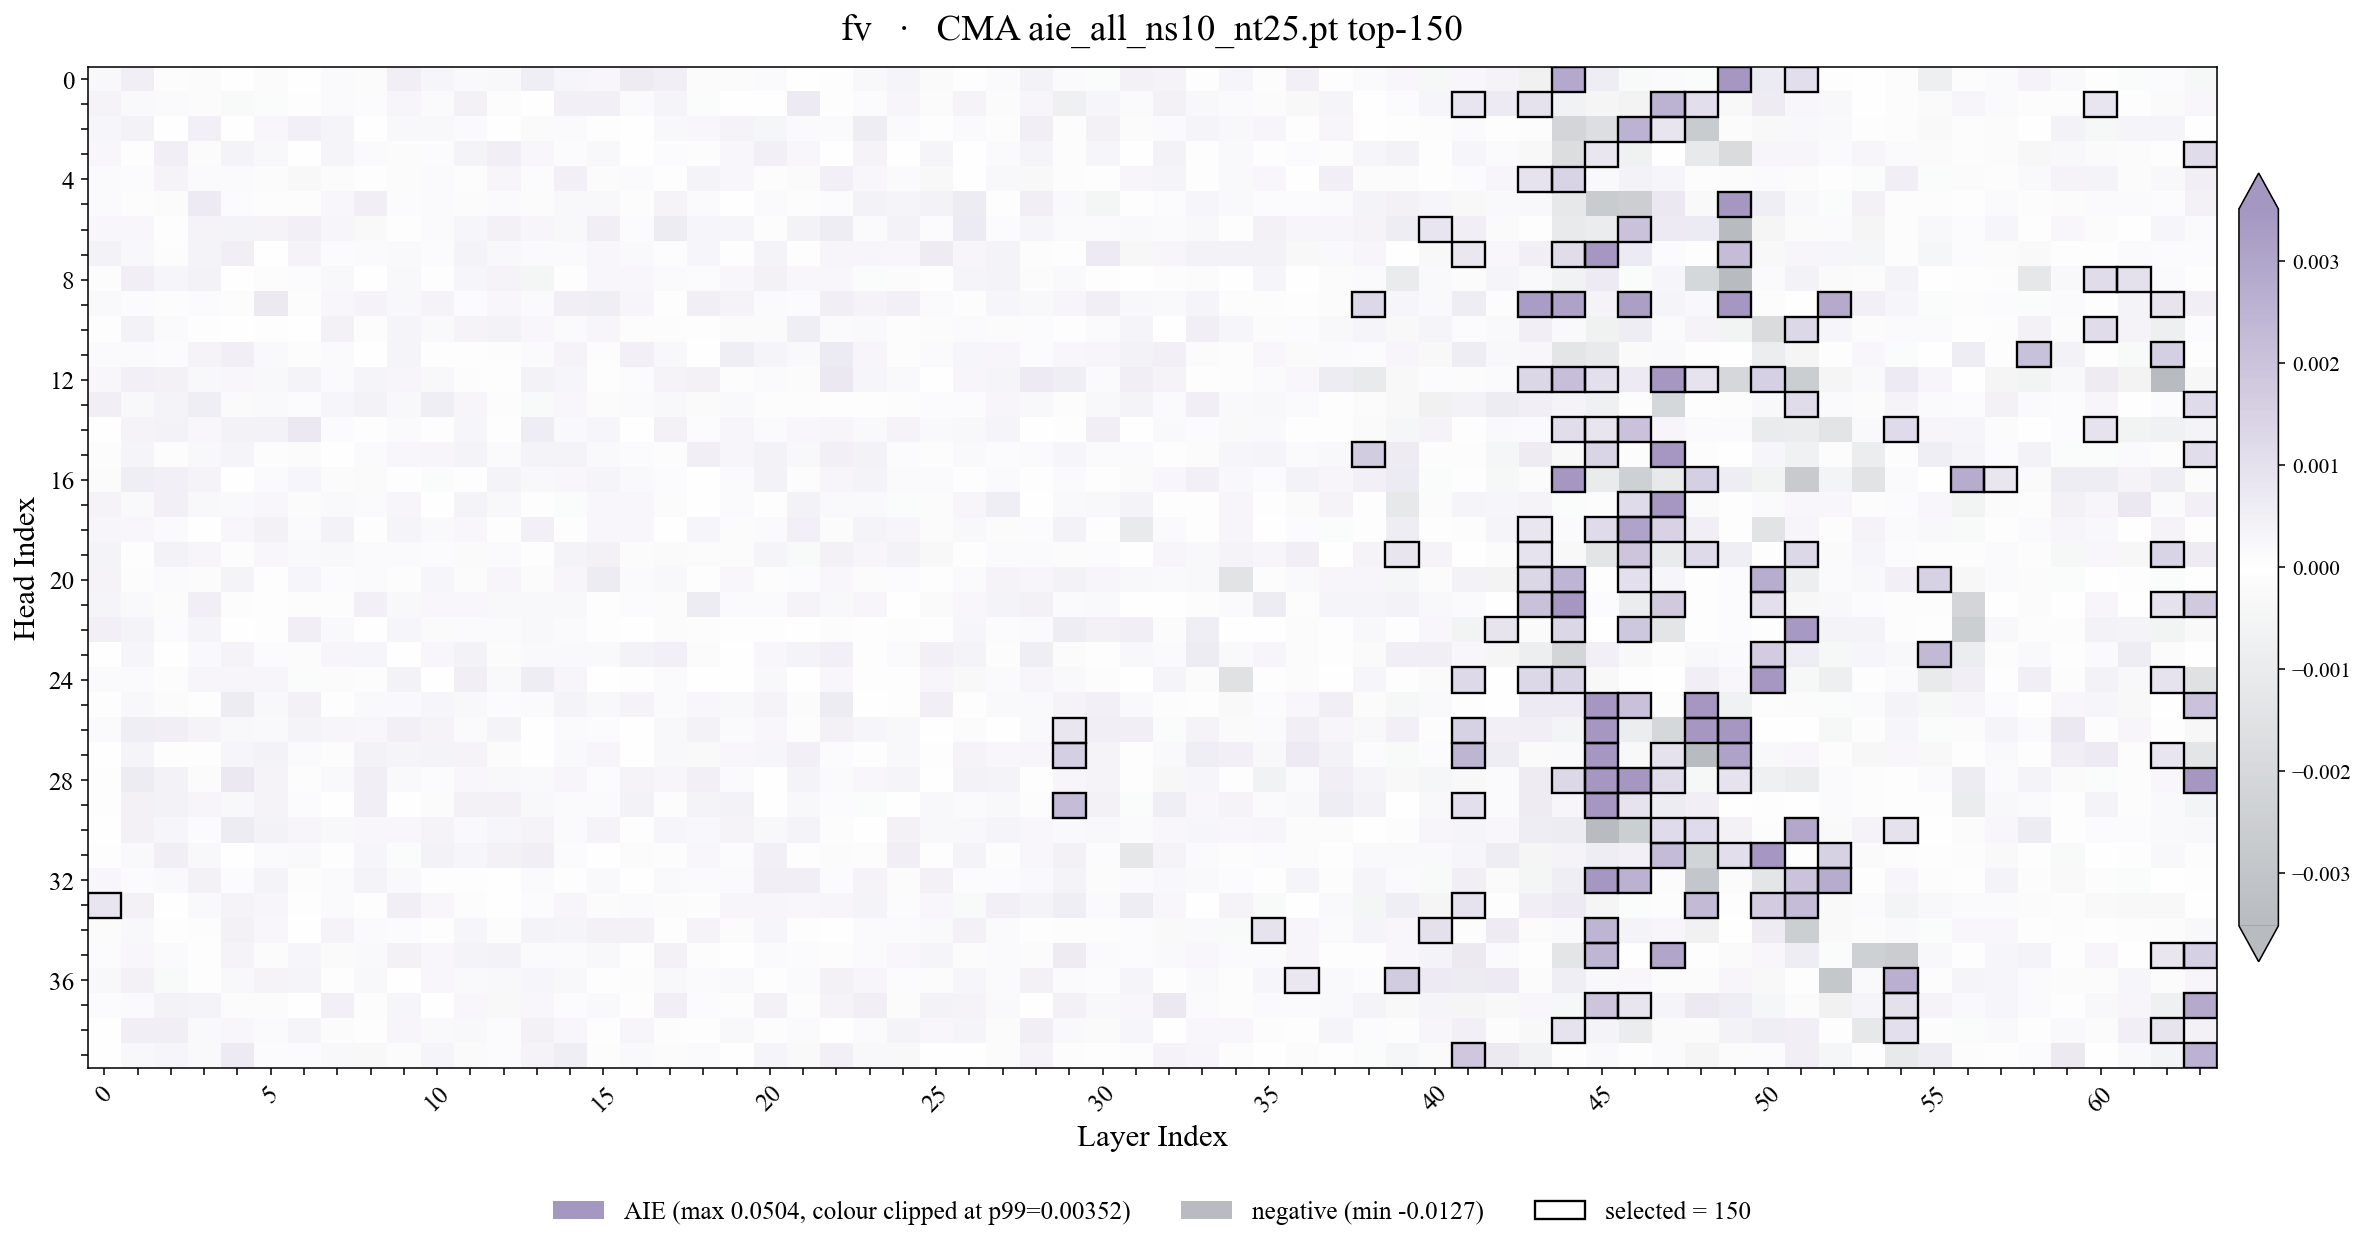

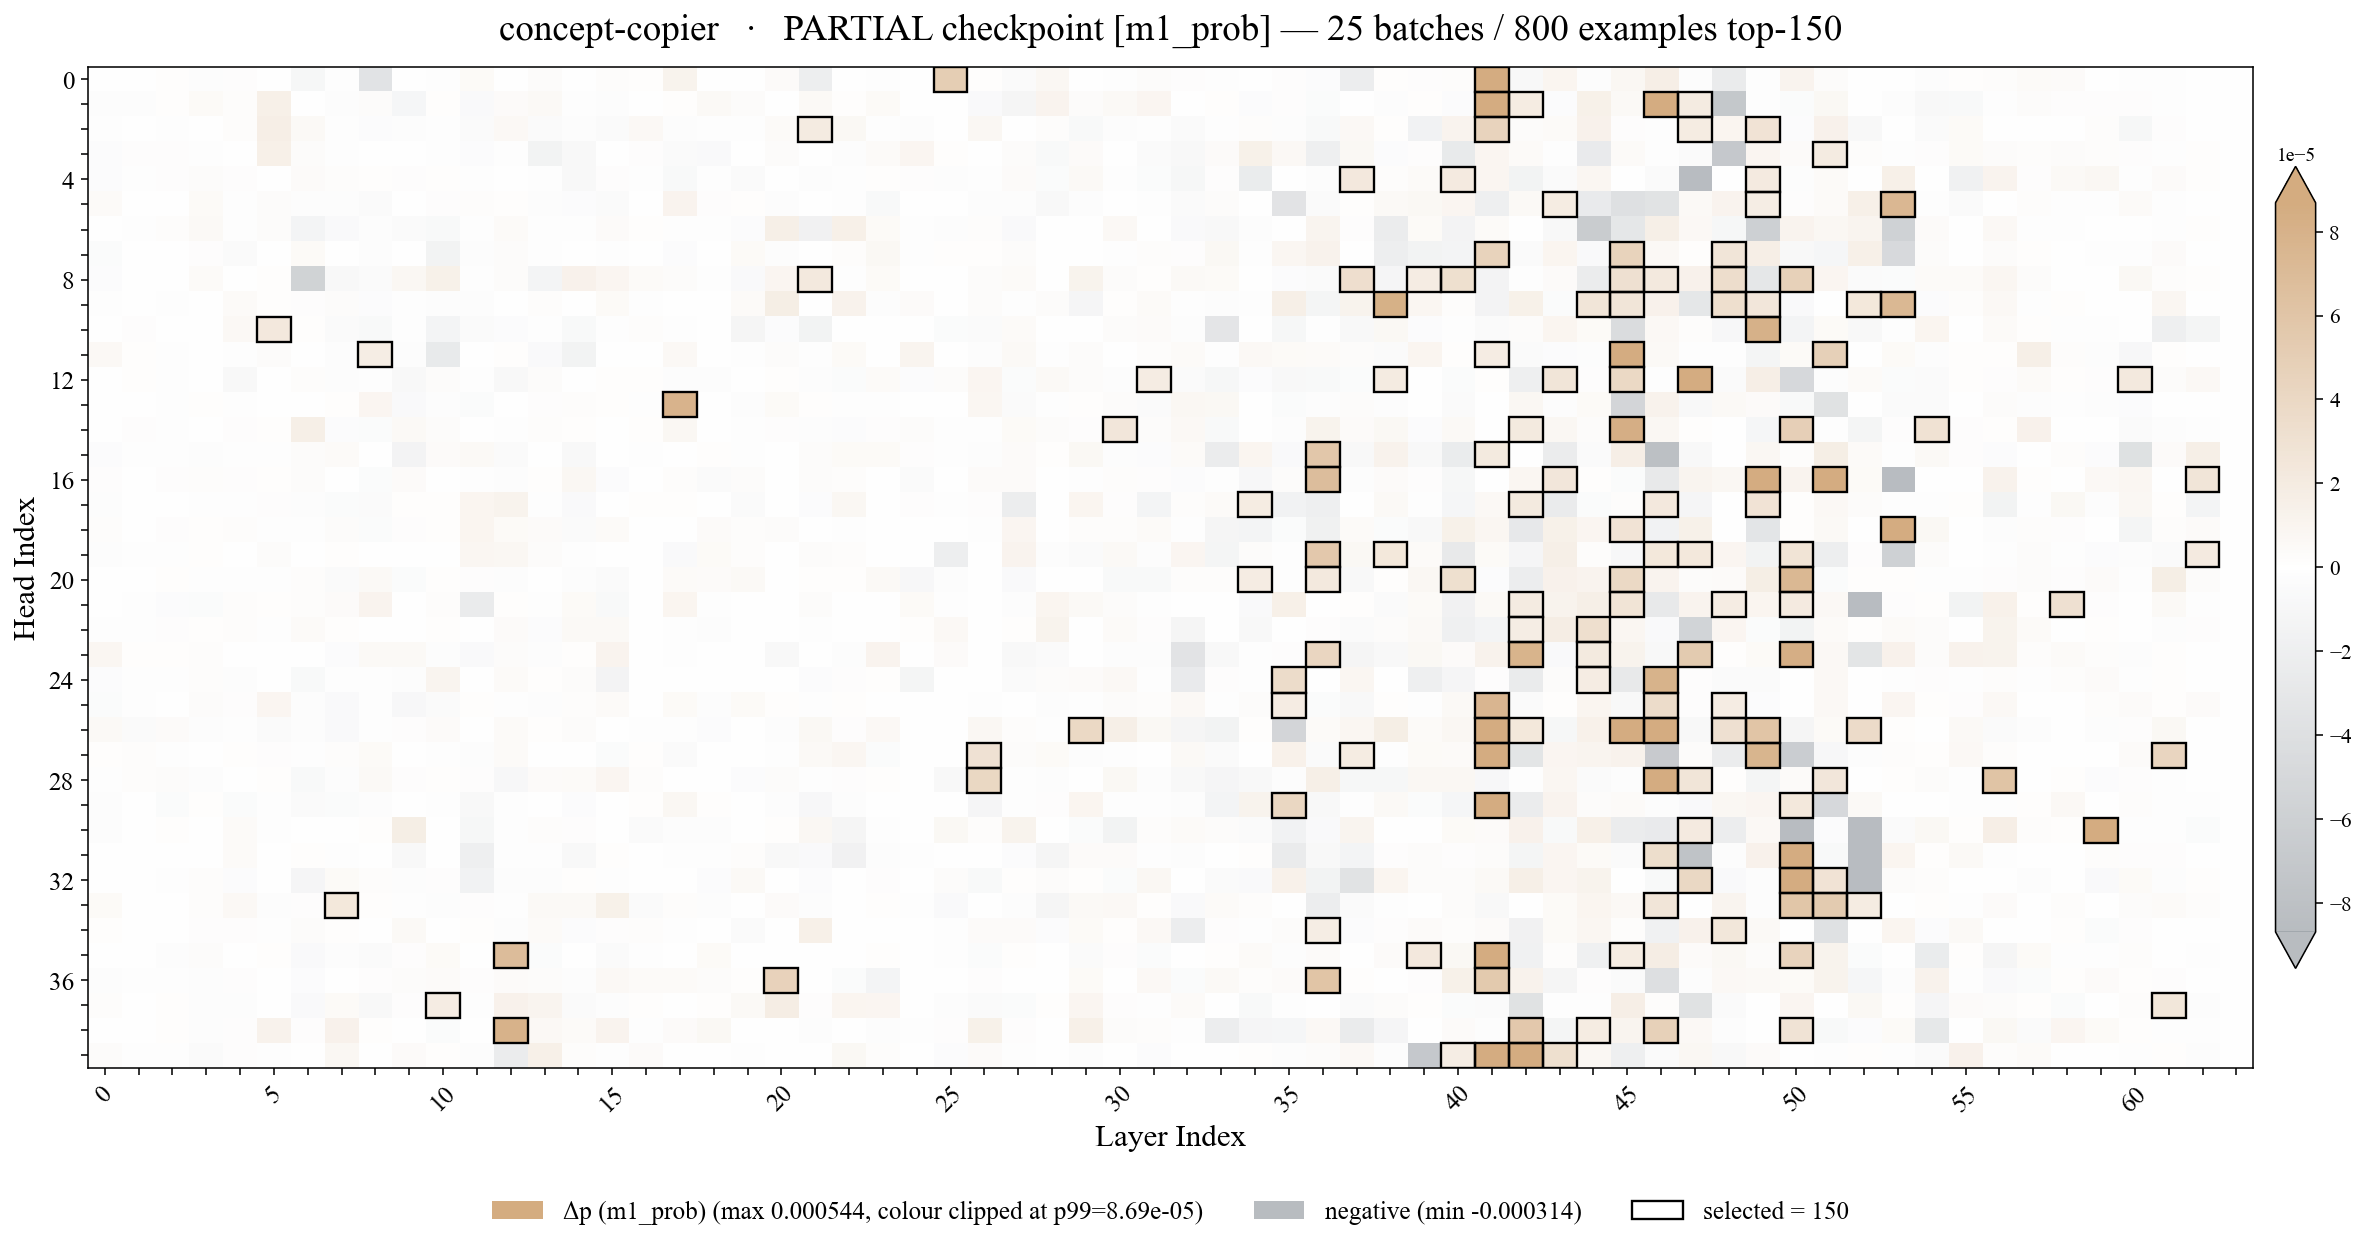

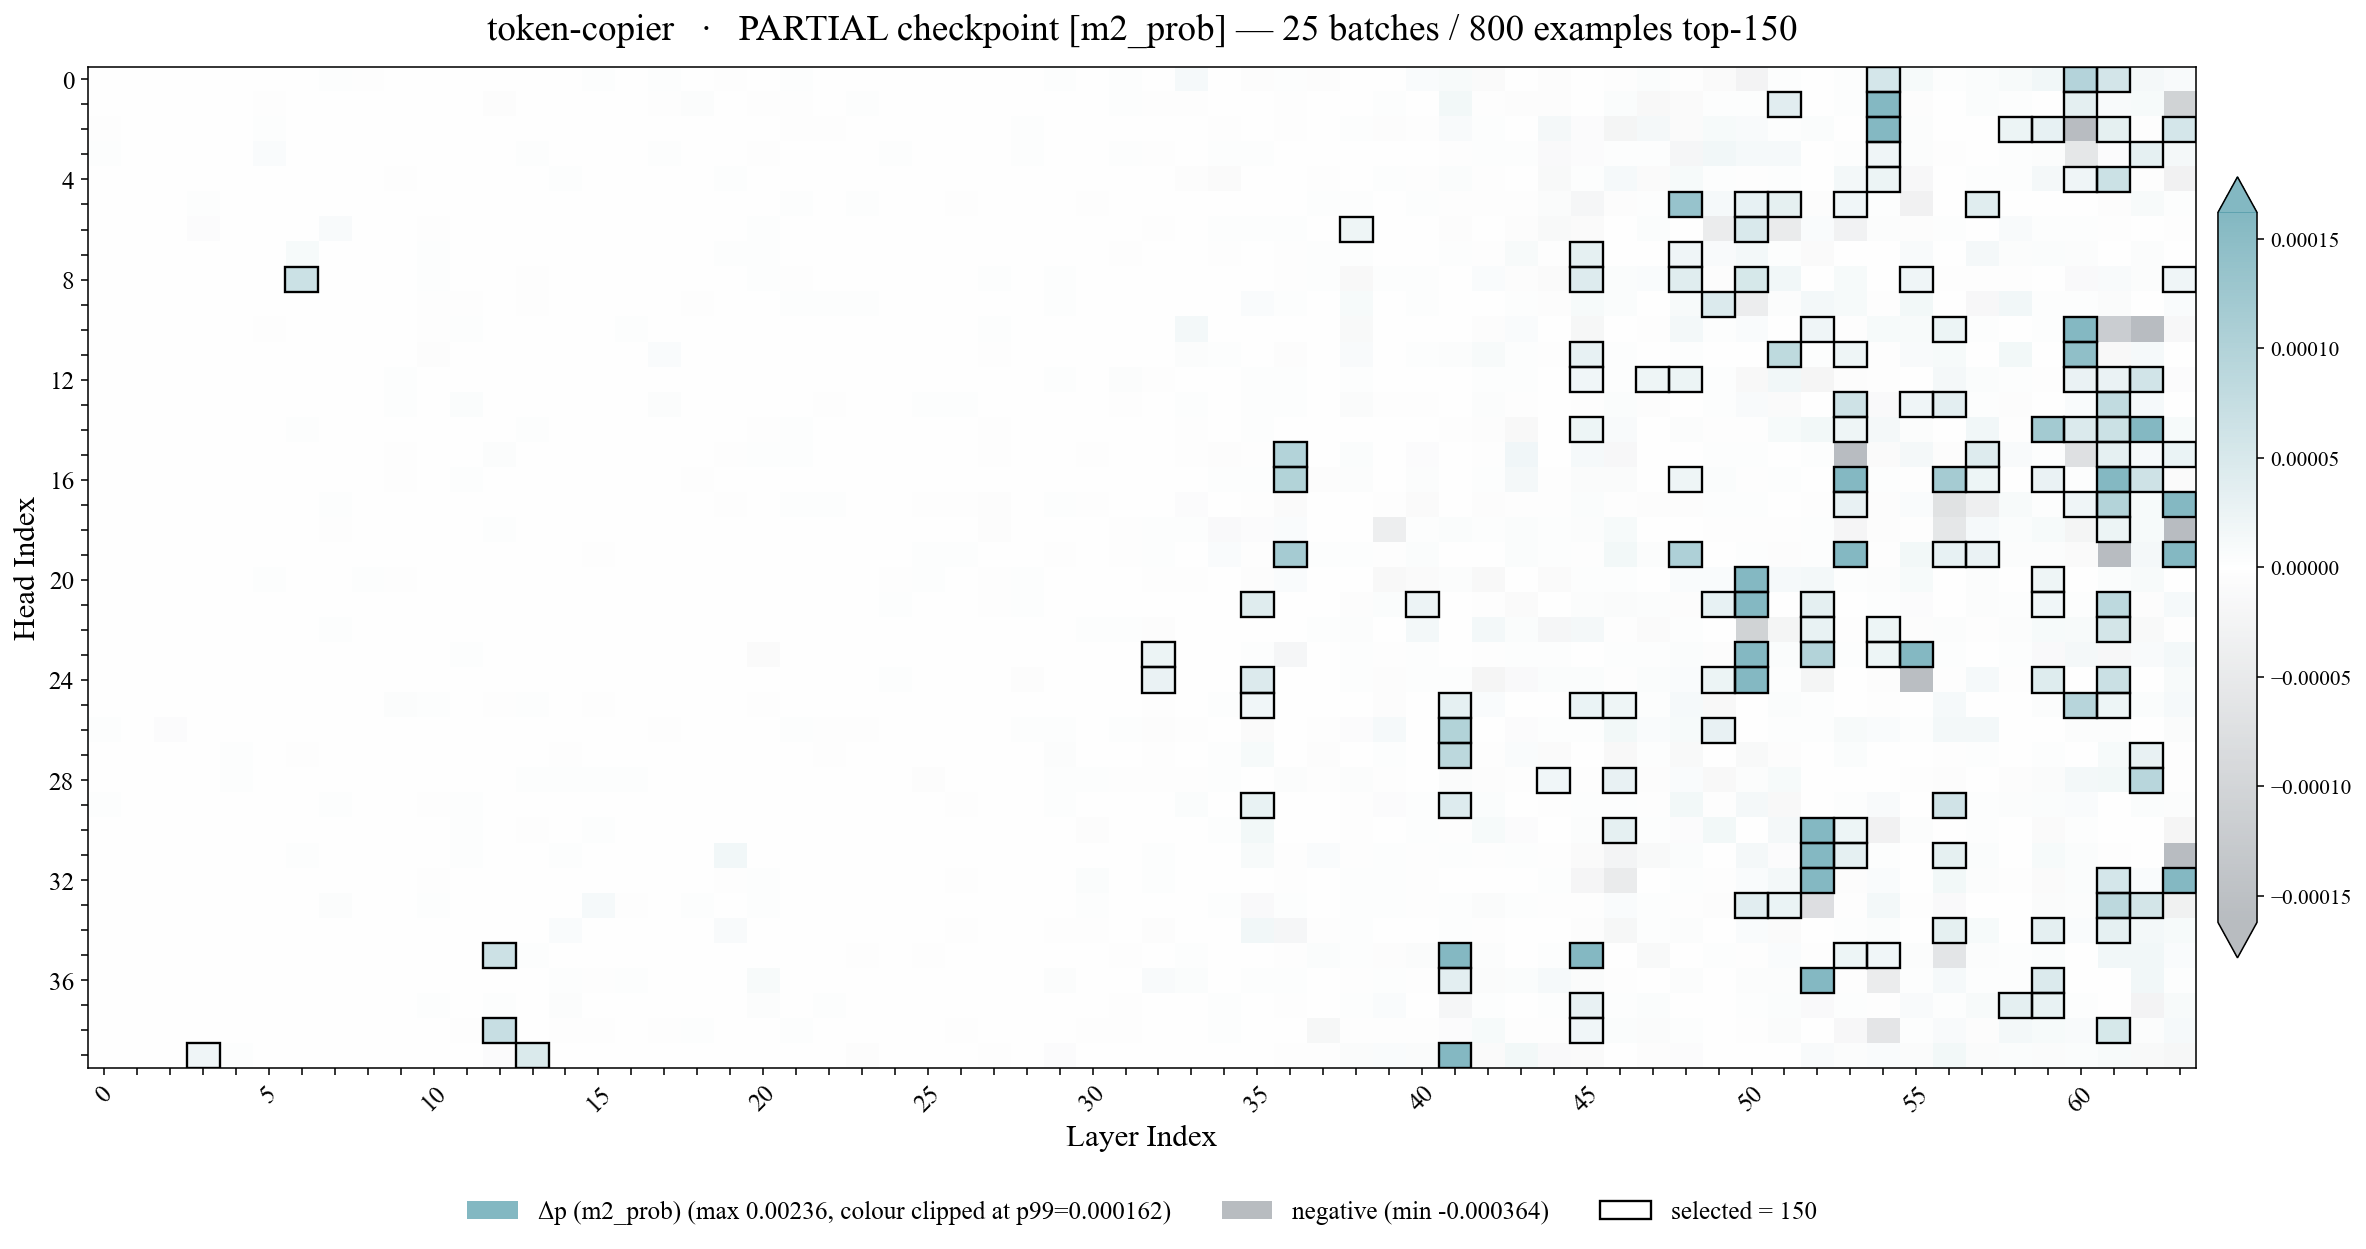

In [6]:
# ── score landscape, one figure per set (style follows __sanity_check §goal-heads) ──
# White = 0 in every panel. Three of the six sets DO contain negatives (fv 24%, concept 44%,
# token 44% of scored heads), so those get a diverging map: matte colour for positive, neutral
# grey for negative, limits symmetric about 0 so white stays exactly zero. The three
# non-negative sets (goal, decision, gaze) use a plain white -> matte ramp from 0 to their max.
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import patches

plt.rcParams["figure.dpi"] = 140
plt.rcParams["font.family"] = "Times New Roman"
SMALL, MEDIUM, BIG = 13, 16, 19

SET_COLOR = {                      # one matte tone per kind of head
    "goal":           "#BF625E",   # terracotta — as in __sanity_check
    "decision":       "#5E7CBF",   # slate
    "gaze":           "#5E9E72",   # sage
    "fv":             "#7E6BA8",   # violet
    "concept-copier": "#C2894B",   # ochre
    "token-copier":   "#4F9AA8",   # teal
}
NEG_COLOR = "#9AA0A6"              # neutral grey: "this score is negative", never a head kind
ALPHA = 0.7
CLIP_PCT = 99.0                    # colour-limit percentile for unbounded (non-mask) scores

def get_ticks(n, skip=5):
    return [str(i) if i % skip == 0 else "" for i in range(n)]

def plot_head_set(hs, name=None):
    """The score landscape for one HeadSet: white at 0, one matte tone per kind, black border on
    selected. Factored out of the per-set loop so the sparsity sweep can call it too."""
    name = name or hs.name
    g = hs.grid.T                                   # (heads, layers): x = layer, y = head
    finite = g[np.isfinite(g)]
    signed = bool((finite < 0).any())
    col = SET_COLOR.get(name, "#BF625E")
    # Mask values and rank percentiles are already on a meaningful [0,1] scale, so show it whole.
    # AIE / Δp / lookback scores are heavy-tailed — a handful of heads carry effects orders of
    # magnitude above the bulk, and scaling to the max renders every other head white. Clip the
    # colour limits at CLIP_PCT instead (the colourbar is marked `extend`); this changes only the
    # colours, never which heads are ringed.
    bounded = bool(finite.min() >= 0.0 and finite.max() <= 1.0)
    if bounded:
        vmin, vmax, clipped = 0.0, 1.0, False
    elif signed:
        M = float(np.percentile(np.abs(finite), CLIP_PCT)); vmin, vmax = -M, M
        clipped = M < float(np.abs(finite).max())
    else:
        vmin, vmax = 0.0, float(np.percentile(finite, CLIP_PCT))
        clipped = vmax < float(finite.max())
    cmap = (LinearSegmentedColormap.from_list(f"{name}_div", [NEG_COLOR, "white", col], N=256)
            if signed else
            LinearSegmentedColormap.from_list(f"{name}_seq", ["white", col], N=256))
    cmap = cmap.copy(); cmap.set_bad("#EFEFEF")     # not scored by this method

    fig, ax = plt.subplots(figsize=(17, 9))
    im = ax.imshow(np.ma.masked_invalid(g), cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax,
                   alpha=ALPHA, interpolation="nearest")
    for l, h in hs.selected:                        # black border = selected by the current config
        ax.add_patch(patches.Rectangle((l - 0.5, h - 0.5), 1, 1, linewidth=1.2,
                                       edgecolor="black", facecolor="none"))
    ax.set_xticks(range(N_LAYER)); ax.set_xticklabels(get_ticks(N_LAYER, 5), rotation=45, fontsize=SMALL)
    ax.set_yticks(range(N_HEADS)); ax.set_yticklabels(get_ticks(N_HEADS, 4), fontsize=SMALL)
    ax.set_xlabel("Layer Index", fontsize=MEDIUM); ax.set_ylabel("Head Index", fontsize=MEDIUM)

    legend = [mpatches.Patch(facecolor=col, alpha=ALPHA,
                             label=f"{hs.score_label} (max {finite.max():.3g}"
                                   + (f", colour clipped at p{CLIP_PCT:g}={vmax:.3g})" if clipped else ")")),
              mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1.2,
                             label=f"selected = {len(hs.selected)}")]
    if signed:
        legend.insert(1, mpatches.Patch(facecolor=NEG_COLOR, alpha=ALPHA,
                                        label=f"negative (min {finite.min():.3g})"))
    # legend below the axes: above it collides with the title at this figure aspect
    ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.11),
              ncol=len(legend), fontsize=SMALL, frameon=False)
    ax.set_title(f"{name}   ·   {hs.provenance}", fontsize=BIG, pad=14)
    ext = ("both" if signed else "max") if clipped else "neither"
    fig.colorbar(im, ax=ax, fraction=0.018, pad=0.01, extend=ext).ax.tick_params(labelsize=SMALL - 2)
    plt.tight_layout(); plt.show()


for _name, _hs in SETS.items():
    plot_head_set(_hs, _name)

### Overlap metrics

Two head sets $A, B$ drawn from $N = L \cdot H$ heads ($L$ layers $\times$ $H$ heads per layer).
$a_\ell, b_\ell$ are how many heads each set selects **in layer $\ell$**, so
$|A| = \sum_\ell a_\ell$.

**Raw overlap**

$$\texttt{Jacc} = \frac{|A \cap B|}{|A \cup B|} \qquad\qquad
  \texttt{ovlp} = \frac{|A \cap B|}{\min(|A|, |B|)}$$

Jaccard is 0 for disjoint sets and 1 for identical ones, but it is **not linear in between**: for
equal-size sets, if $f$ is the fraction of each set that is shared then $J = f/(2-f)$, i.e.
$f = 2J/(1+J)$ — so $J = 0.13$ means $\approx 23\%$ shared, not 13%. It is also capped at
$\min(|A|,|B|)/\max(|A|,|B|)$, so with sets of 122–181 heads its cells sit on **different scales
and cannot be compared across pairs**. `ovlp` has neither problem: it reaches 1 whenever the smaller
set is contained in the larger, and reads directly as "what fraction of the smaller set is shared".

**Against a uniform null** — both sets uniformly random over all $N$ heads:

$$\mathbb{E}_{\text{unif}}[|A \cap B|] = \frac{|A|\,|B|}{N}
  \qquad\qquad \texttt{lift\_u} = \frac{|A \cap B|}{\mathbb{E}_{\text{unif}}}$$

This is exact under its own assumptions ($|A \cap B|$ is hypergeometric with that mean), but the
assumption is wrong here: **every one of these sets concentrates by depth**. Two sets that merely
share a layer preference land far above this baseline with no relation in head identity, so
`lift_u` systematically overstates.

**Against a layer-matched null** — condition on both depth profiles and randomise only *within* each
layer. Per layer the intersection is $\mathrm{Hypergeom}(H, a_\ell, b_\ell)$, and layers are
independent, so means and variances add:

$$\texttt{E\_lay} = \sum_\ell \frac{a_\ell b_\ell}{H}
  \qquad
  \mathrm{Var} = \sum_\ell b_\ell \frac{a_\ell}{H}\frac{H - a_\ell}{H}\frac{H - b_\ell}{H-1}$$

$$\texttt{lift\_l} = \frac{|A \cap B|}{\texttt{E\_lay}}
  \qquad\qquad
  z = \frac{|A \cap B| - \texttt{E\_lay}}{\sqrt{\mathrm{Var}}}$$

**How to read it.** `lift_l` is the one to trust — it isolates *do they pick the same heads* from
*do they live at the same depth*. `z` says whether that lift is bigger than the null's own spread;
$|z| \lesssim 2$ is consistent with "same depths, different heads". Note the layer-matched null
conditions on both profiles **by construction**, so it cannot tell you whether the shared depth is
itself meaningful — that is a separate question, and for goal vs decision arguably the more
interesting one.

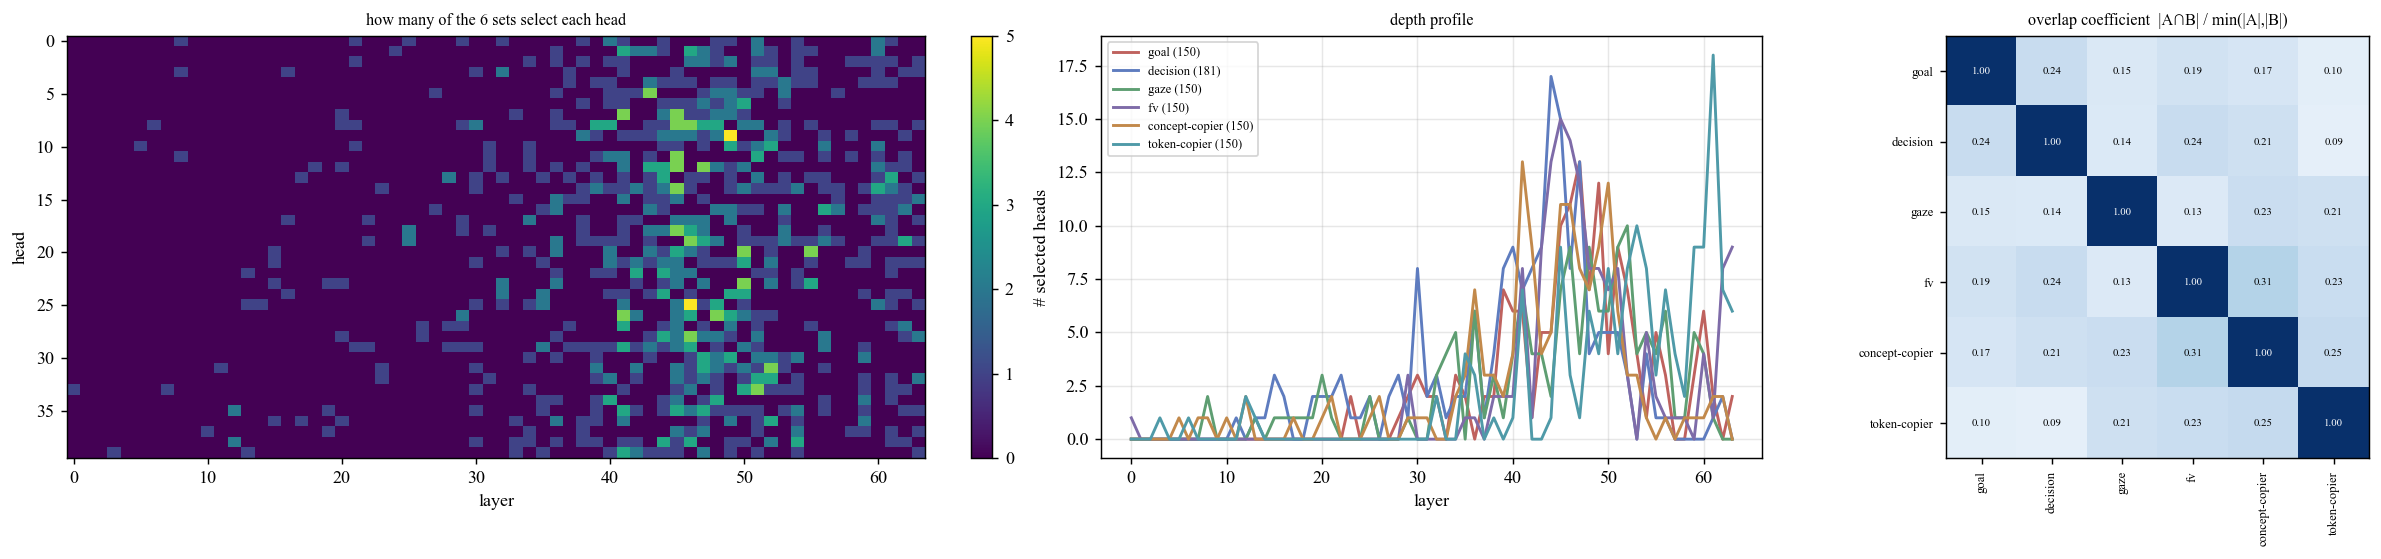

                set overlap — uniform vs layer-matched null                
┏━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━┓
┃pair               ┃ |∩| ┃  Jacc ┃  ovlp ┃ lift_u ┃ E_lay ┃ lift_l ┃    z┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━┩
│concept ∩ token    │  38 │ 0.145 │ 0.253 │  4.32x │  15.4 │  2.46x │ +7.1│
│fv ∩ token         │  35 │ 0.132 │ 0.233 │  3.98x │  17.1 │  2.05x │ +5.3│
│fv ∩ concept       │  46 │ 0.181 │ 0.307 │  5.23x │  24.0 │  1.92x │ +5.9│
│gaze ∩ token       │  31 │ 0.115 │ 0.207 │  3.53x │  16.5 │  1.88x │ +4.3│
│gaze ∩ concept     │  34 │ 0.128 │ 0.227 │  3.87x │  19.1 │  1.78x │ +4.2│
│goal ∩ decision    │  36 │ 0.122 │ 0.240 │  3.39x │  23.6 │  1.52x │ +3.3│
│decision ∩ fv      │  36 │ 0.122 │ 0.240 │  3.39x │  27.7 │  1.30x │ +2.1│
│decision ∩ concept │  31 │ 0.103 │ 0.207 │  2.92x │  24.1 │  1.29x │ +1.8│
│goal ∩ concept     │  25 │ 0.091 │ 0.167 │  2.84x │  21.1 │  1.18x │ +1.1│
│goal ∩ fv          │  29 │ 0.107 │ 0.193 │  3.30x │  24.8 │  1.17x │ +1.1│
│decision ∩ gaze    │  21 │ 0.068 │ 0.140 │  1.98x │  18.0 │  1.17x │ +0.9│
│goal ∩ gaze        │  22 │ 0.079 │ 0.147 │  2.50x │  19.2 │  1.14x │ +0.8│
│decision ∩ token   │  13 │ 0.041 │ 0.087 │  1.23x │  12.2 │  1.07x │ +0.3│
│gaze ∩ fv          │  20 │ 0.071 │ 0.133 │  2.28x │  18.7 │  1.07x │ +0.4│
│goal ∩ token       │  15 │ 0.053 │ 0.100 │  1.71x │  15.8 │  0.95x │ -0.2│
└───────────────────┴─────┴───────┴───────┴────────┴───────┴────────┴─────┘

Read the layer-matched lift, not the uniform one: the uniform null ignores that every set concentrates by depth, so
it credits shared depth as shared identity. `z` is against the layer-matched null (sum of per-layer 
hypergeometrics). Jaccard is capped at min/max of the set sizes, so its cells are not comparable across pairs — use
the overlap coefficient.

In [7]:
# ── where the sets live, and how much they overlap ──────────────────────────
import itertools

names = list(SETS)
cover = np.zeros((N_LAYER, N_HEADS))
for hs in SETS.values():
    for l, h in hs.selected:
        cover[l, h] += 1
PROF = {n: np.bincount([l for l, _ in SETS[n].selected], minlength=N_LAYER) for n in names}

def overlap_stats(a, b):
    """Intersection of two head sets against two null models.

    uniform    — both sets are uniformly random over all N_LAYER*N_HEADS heads:
                 E = |A||B| / N.  Cheap, but WRONG for these sets: every one of them
                 concentrates by depth, so two sets that merely share a layer preference
                 overlap far above this baseline with no relation in head identity.
    layer-matched — condition on each set's per-layer counts and randomise only WITHIN a
                 layer.  Per layer the intersection is Hypergeometric(H, a_l, b_l), and
                 layers are independent, so the mean and variance add.  This isolates
                 "do they pick the same heads" from "do they live at the same depth".
    """
    A, B = SETS[a].key, SETS[b].key
    i = len(A & B)
    e_u = len(A) * len(B) / (N_LAYER * N_HEADS)
    al, bl = PROF[a].astype(float), PROF[b].astype(float)
    H = N_HEADS
    e_l = float((al * bl / H).sum())
    var = float((bl * (al / H) * ((H - al) / H) * ((H - bl) / (H - 1))).sum())
    z = (i - e_l) / np.sqrt(var) if var > 0 else np.nan
    return dict(i=i, nA=len(A), nB=len(B),
                jac=i / len(A | B) if A | B else 0.0,
                ovl=i / min(len(A), len(B)) if A and B else 0.0,
                e_u=e_u, lift_u=i / e_u if e_u else np.nan,
                e_l=e_l, lift_l=i / e_l if e_l else np.nan, z=z)

STATS = {(a, b): overlap_stats(a, b) for a, b in itertools.combinations(names, 2)}

fig, axes = plt.subplots(1, 3, figsize=(19, 4.4), dpi=130,
                         gridspec_kw={"width_ratios": [2.1, 1.5, 1.3]})

im = axes[0].imshow(cover.T, aspect="auto", origin="upper", cmap="viridis",
                    vmin=0, vmax=max(1, cover.max()), interpolation="nearest")
axes[0].set_title(f"how many of the {len(names)} sets select each head", fontsize=9)
axes[0].set_xlabel("layer"); axes[0].set_ylabel("head")
fig.colorbar(im, ax=axes[0], fraction=0.023)

for n in names:
    axes[1].plot(PROF[n], lw=1.6, color=SET_COLOR.get(n), label=f"{n} ({len(SETS[n].selected)})")
axes[1].set_xlabel("layer"); axes[1].set_ylabel("# selected heads")
axes[1].set_title("depth profile", fontsize=9); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7)

# Overlap COEFFICIENT, not Jaccard: Jaccard is capped at min(|A|,|B|)/max(|A|,|B|), so with sets of
# 122-181 heads its cells sit on different scales and are not comparable. Jaccard is still in the
# table below for reference.
M = np.eye(len(names))
for (a, b), s in STATS.items():
    M[names.index(a), names.index(b)] = M[names.index(b), names.index(a)] = s["ovl"]
im = axes[2].imshow(M, cmap="Blues", vmin=0, vmax=1)
axes[2].set_xticks(range(len(names))); axes[2].set_xticklabels(names, rotation=90, fontsize=7)
axes[2].set_yticks(range(len(names))); axes[2].set_yticklabels(names, fontsize=7)
for r in range(len(names)):
    for c_ in range(len(names)):
        axes[2].text(c_, r, f"{M[r, c_]:.2f}", ha="center", va="center", fontsize=6,
                     color="white" if M[r, c_] > 0.5 else "black")
axes[2].set_title("overlap coefficient  |A∩B| / min(|A|,|B|)", fontsize=9)
plt.tight_layout(); plt.show()

SHORT = {"concept-copier": "concept", "token-copier": "token"}
def _s(n): return SHORT.get(n, n)

t = Table(title="set overlap — uniform vs layer-matched null", pad_edge=False)
t.add_column("pair", justify="left", no_wrap=True)
for c_ in ["|∩|", "Jacc", "ovlp", "lift_u", "E_lay", "lift_l", "z"]:
    t.add_column(c_, justify="right", no_wrap=True)
for (a, b), s in sorted(STATS.items(), key=lambda kv: -kv[1]["lift_l"]):
    t.add_row(f"{_s(a)} ∩ {_s(b)}", str(s["i"]), f"{s['jac']:.3f}", f"{s['ovl']:.3f}",
              f"{s['lift_u']:.2f}x", f"{s['e_l']:.1f}", f"{s['lift_l']:.2f}x", f"{s['z']:+.1f}")
rich_print(t)
rich_print("[grey58]Read the layer-matched lift, not the uniform one: the uniform null ignores that "
           "every set concentrates by depth, so it credits shared depth as shared identity. `z` is "
           "against the layer-matched null (sum of per-layer hypergeometrics). Jaccard is capped at "
           "min/max of the set sizes, so its cells are not comparable across pairs — use the "
           "overlap coefficient.[/grey58]")

In [8]:
# ── export each selection as json for `eval_goalscope.py --heads <path>.json` ──
from pathlib import Path
# eval_goalscope keys its run dir on the file STEM, so the config is baked into the basename:
# two selections must never share one. It also rejects --goal_threshold/--goal_band alongside a
# json head set, which is why the config has to live in the filename rather than on the CLI.
EXPORT_DIR = Path(os.path.dirname(RES)) / "head_sets" / SLUG
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def _tag(hs):
    """Config descriptor for the filename. MUST include every knob that changes the SELECTION —
    eval_goalscope keys its run dir on the file stem, so two selections sharing a basename would
    resume each other's samples (and the second export would silently overwrite the first)."""
    c = hs.cfg
    if hs.name == "goal":
        if c.get("topk") is not None:
            body = f"{c.get('tag') or 'path'}_top{c['topk']}"
        else:
            b = c["band"]; body = f"{c.get('tag') or 'path'}_thr{c['threshold']:g}_band{b[0]}-{b[1]}"
    elif hs.name == "decision":
        body = (f"{c.get('tag') or 'path'}_top{c['topk']}" if c.get("topk") is not None
                else f"{c.get('tag') or 'path'}_thr{c['threshold']:g}")
    elif hs.name == "gaze":
        body = f"q{c['q_span']}_{c['compare']}_top{c['topk']}"
    elif hs.name == "fv":
        body = (f"cma_top{c['topk']}" if c["source"] == "cma"
                else f"mask_lam{c['mask_lam']}_thr{c['mask_threshold']:g}")
    else:
        body = f"top{c['topk']}"
    # ckpt=None (the final mask) adds nothing, so every file exported before `ckpt` existed keeps
    # its current name and stays valid.
    ck = c.get("ckpt")
    if ck is not None:
        # a string ckpt is a filename; keep only the epoch digits so the stem stays readable
        s_ck = str(ck) if isinstance(ck, int) else "".join(ch for ch in str(ck) if ch.isdigit())
        body += f"_ck{s_ck or str(ck).replace('.pt','')}"
    return body


def head_set_path(hs, export_dir=None):
    """`<dir>/<set>__<config>.json` — the single source of truth for export naming."""
    return Path(export_dir or EXPORT_DIR) / f"{hs.name.replace('-', '_')}__{_tag(hs)}.json"


for name, hs in SETS.items():
    p = head_set_path(hs)
    p.write_text(json.dumps([[int(l), int(h)] for l, h in sorted(hs.selected)]))
    rich_print(f"[green]{len(hs.selected):4d}[/green] heads -> {p}")

rich_print("\n[bold]ready to use:[/bold]")
for name, hs in SETS.items():
    p = head_set_path(hs)
    rich_print(f"[grey58]  python -m scripts.evaluation.eval_goalscope --mode faithfulness "
               f"--heads {p} --strategy replace --alpha 1.0[/grey58]")

 150 heads -> /disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_top150.json

 181 heads -> /disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/decision__lam10.0_thr0.8.json

 150 heads -> /disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/gaze__q15_mean_top150.json

 150 heads -> /disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/fv__cma_top150.json

 150 heads -> /disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/concept_copier__top150.json

 150 heads -> /disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/token_copier__top150.json

... (3 outputs left out)

  python -m scripts.evaluation.eval_goalscope --mode faithfulness --heads 
/disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/gaze__q15_mean_top150.json --strategy 
replace --alpha 1.0

  python -m scripts.evaluation.eval_goalscope --mode faithfulness --heads 
/disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/fv__cma_top150.json --strategy replace 
--alpha 1.0

  python -m scripts.evaluation.eval_goalscope --mode faithfulness --heads 
/disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/concept_copier__top150.json --strategy 
replace --alpha 1.0

  python -m scripts.evaluation.eval_goalscope --mode faithfulness --heads 
/disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/token_copier__top150.json --strategy 
replace --alpha 1.0

## Sparsity sweep — select, inspect, export

Load any head set at any sparsity level, look at what the selection actually is, then write it out
for `eval_goalscope.py --heads <path>.json`.

`head_stats` reports the things that decide whether a selection is meaningful:

* **`n_sel`** vs **`n_scored`** / **`n_nonzero`** — how much of the scored grid the cut keeps. For a
  trained mask most heads are exactly 0, so `n_nonzero` is the real ceiling on a top-k.
* **`n_tied@K`** — how many heads share the K-th score. **> 1 means the cut runs through a tie
  block**, so which heads land inside is index order, not importance. The masks saturate at exactly
  1.0 (117 of Qwen-32B's goal heads), so every `k` below that count selects an arbitrary subset of
  the maximal heads. This is the single most important number here.
* **`>thr`** — heads above a few reference thresholds, for comparison with the threshold-based rule.
* **layer span / IQR / top-3 layers** — whether the selection is concentrated or spread.

The exported filename carries the config, because `eval_goalscope` keys its run dir on the file
**stem** — two selections sharing a basename would resume each other's samples.

In [9]:
# ── stats for one selection ────────────────────────────────────────────────
from collections import Counter
from pathlib import Path
from rich.box import SIMPLE_HEAVY

def head_stats(hs, thresholds=(0.5, 0.8, 0.9, 0.99)):
    """Summary numbers for one HeadSet — see the markdown above for what each one is for."""
    g = hs.grid
    finite = g[np.isfinite(g)]
    vals = np.sort(finite)[::-1]
    k = len(hs.selected)
    at_k = float(vals[k - 1]) if 0 < k <= len(vals) else float("nan")
    n_tied = int((vals == at_k).sum()) if np.isfinite(at_k) else 0
    ls = [l for l, _ in hs.selected]
    by_layer = Counter(ls)
    q1, q3 = (np.percentile(ls, [25, 75]) if ls else (np.nan, np.nan))
    return dict(
        name=hs.name, n_sel=k,
        n_scored=int(finite.size), n_nonzero=int((finite != 0).sum()),
        score_at_1=float(vals[0]) if vals.size else float("nan"),
        score_at_k=at_k, n_tied_at_k=n_tied,
        **{f">{t:g}": int((finite > t).sum()) for t in thresholds},
        layer_lo=(min(ls) if ls else None), layer_hi=(max(ls) if ls else None),
        layer_iqr=(f"{q1:.0f}-{q3:.0f}" if ls else None),
        top_layers=" ".join(f"L{l}:{n}" for l, n in by_layer.most_common(3)),
        provenance=hs.provenance,
    )

def stats_table(rows, title):
    t = Table(title=title, box=SIMPLE_HEAVY, pad_edge=False, title_justify="left")
    # `head_stats` returns more than this (the >thr counts, IQR); the table keeps only what
    # fits on one line — pull the rest off the returned dicts when needed.
    for c_, j in [("name", "left"), ("n_sel", "right"), ("n_nz", "right"), ("s@1", "right"),
                  ("s@K", "right"), ("tied@K", "right"), ("layers", "right")]:
        t.add_column(c_, justify=j, no_wrap=True)
    t.add_column("top layers", justify="left", overflow="fold")
    for r in rows:
        tied = r["n_tied_at_k"]
        # tied>1: the cut runs through a tie block -> index order, not importance.
        # s@K==0 with a zero-score tie block: k has run past the scored heads entirely.
        flag = " !!" if (tied > 1 and r["score_at_k"] == 0) else (" *" if tied > 1 else "")
        t.add_row(r["name"], str(r["n_sel"]), str(r["n_nonzero"]),
                  f"{r['score_at_1']:.3g}", f"{r['score_at_k']:.3g}", f"{tied}{flag}",
                  f"{r['layer_lo']}-{r['layer_hi']}", r["top_layers"])
    rich_print(t)
    rich_print("[grey58]* tied@K > 1: the cut falls inside a tie block, so which heads land inside "
               "is index order, not importance.  !! also s@K == 0: k has run past every scored "
               "head and is padding the selection with zero-score ones.[/grey58]")


def layer_hist(rows_hs, title):
    """Layer-wise distribution of several selections on one axis."""
    fig, ax = plt.subplots(figsize=(11, 3.2), dpi=130)
    for lbl, hs in rows_hs:
        prof = np.bincount([l for l, _ in hs.selected], minlength=N_LAYER)
        ax.plot(prof, lw=1.5, label=f"{lbl} (n={len(hs.selected)})")
    ax.set_xlabel("layer"); ax.set_ylabel("# selected"); ax.grid(alpha=.3)
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7, ncol=3)
    plt.tight_layout(); plt.show()

mask/score grids before selection · Qwen2.5-Coder-32B-Instruct                                        
                                                                                                      
 candidate    n_nz     %nz   max   n_sat   nz mean   nz med     p90   >0.5   >0.9   layers   usable k 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 lam1          845   33.0%     1     169     0.525    0.458       1    406    246     0-63    169-845 
 lam100        100    3.9%     1      49     0.809        1       1     81     78     0-61     49-100 
 lam20         257   10.0%     1     117     0.686    0.986       1    178    137     0-63    117-257 
 lam5          341   13.3%     1     116     0.587    0.772       1    184    156     0-63    116-341 
 lam50         141    5.5%     1      71     0.783        1       1    111    100     0-63     71-141 
 lam20@ep10    685   26.8%     1      67     0.415    0.326   0.995    242     93     0-63     67-685 
 lam20@ep30    269   10.5%     1     108     0.684     0.85       1    177    125     0-63    108-269 
 lam20@ep50    257   10.0%     1     117     0.686    0.986       1    178    137     0-63    117-257

`n_sat` = heads tied at the maximum, so it is the SMALLEST top-k that ranks rather than tie-breaks by index; `n_nz`
is the LARGEST before zero-score heads get padded in. `usable k` is that range — pick a checkpoint whose range 
covers the sparsity levels you want, then set SWEEP_CFG accordingly.

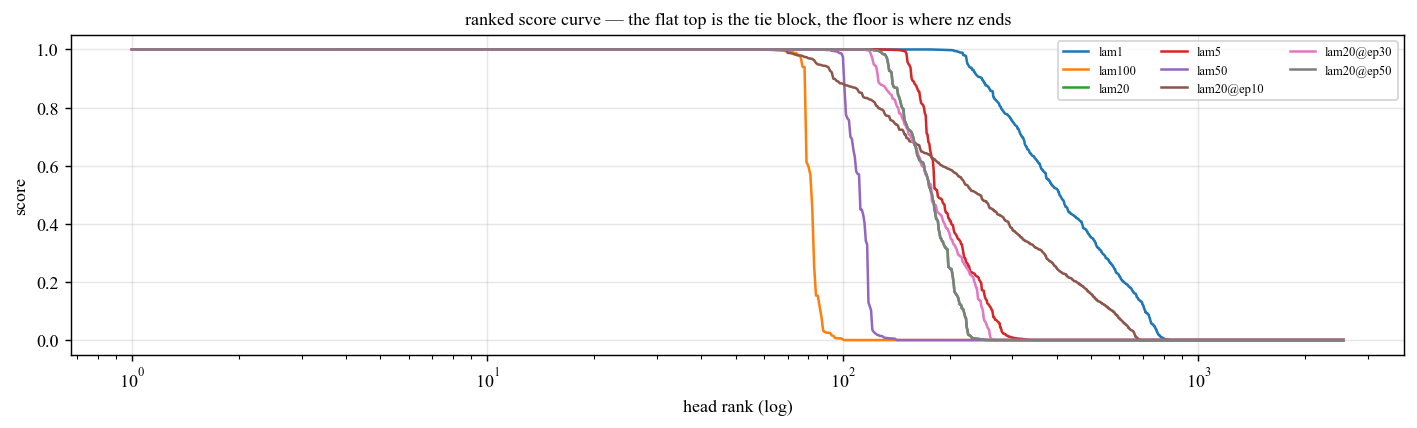

In [20]:
# ── the sweep: its OWN config, then load / inspect / export at each sparsity level ──
# SWEEP_CFG is deliberately independent of the module-level CFG: the sweep often wants a different
# lambda, checkpoint or artifact from the one driving the figures above, and editing CFG for that
# would silently change §1-§3 too. `topk` is omitted here — the sweep supplies it per level.
SWEEP_CFG = dict(
    goal     = dict(tag="lam5", threshold=None, band=None, path=None, ckpt=None),
    # decision = dict(version="conditions", tag="lam10.0", threshold=None, path=None, ckpt=None),
    # gaze     = dict(version="conditions", q_span=15, compare="mean", path=None),
    # fv       = dict(source="cma", mask_lam="1", mask_threshold=0.5, path=None, ckpt=None),
    # concept  = dict(allow_partial=True, path=None),
    # token    = dict(allow_partial=True, path=None),
)


# ── which checkpoint? global mask stats BEFORE any head selection ──────────
def mask_grid(name, cfg):
    """The raw score grid for a config, with no commitment to a selection rule.

    `topk=1` is a placeholder only: the grid is whatever the artifact contains, so it does not
    depend on how many heads you later cut. Everything else (path / tag / ckpt resolution) is the
    loader's, so what is inspected here is exactly what the sweep will select from."""
    key = CFG_KEY.get(name, name)
    c = dict(cfg, topk=1)
    if key in ("goal", "decision"):
        c["threshold"] = None
    if key == "goal":
        c["band"] = None
    hs = load_set(name, c)
    return hs.grid, hs.provenance.replace(" top-1", "")


def grid_stats(grid):
    """Global properties of one mask/score grid — what decides whether a checkpoint is usable.

    `n_sat` (heads tied at the maximum) is the SMALLEST meaningful top-k: below it the cut falls
    inside the tie block and selects by index order. `n_nz` is the LARGEST: above it the selection
    is padded with zero-score heads. Together they give the usable k range for that artifact."""
    finite = grid[np.isfinite(grid)]
    nz = finite[finite != 0]
    mx = float(finite.max()) if finite.size else float("nan")
    n_sat = int((finite == mx).sum()) if finite.size else 0
    ls = sorted({int(l) for l, _ in np.argwhere(np.nan_to_num(grid, nan=0.0) != 0)})
    return dict(
        n_scored=int(finite.size), n_nz=int(nz.size),
        frac_nz=(nz.size / finite.size if finite.size else float("nan")),
        max=mx, n_sat=n_sat,
        nz_mean=(float(nz.mean()) if nz.size else float("nan")),
        nz_median=(float(np.median(nz)) if nz.size else float("nan")),
        p90=(float(np.percentile(nz, 90)) if nz.size else float("nan")),
        gt05=int((finite > 0.5).sum()), gt09=int((finite > 0.9).sum()),
        layer_lo=(ls[0] if ls else None), layer_hi=(ls[-1] if ls else None),
        n_layers_touched=len(ls),
    )


def discover_goal_ckpts(tag=None, epochs="all"):
    """Candidate (label, cfg) pairs for the goal mask: every lambda tag, plus every saved epoch
    checkpoint of `tag` if asked. Auto-discovered so a new sweep on disk shows up without edits."""
    root = os.path.join(RES, "localization", SLUG)
    out = []
    for t in sorted(os.listdir(root)):
        if os.path.isfile(os.path.join(root, t, "head_mask.pt")):
            out.append((t, dict(SWEEP_CFG["goal"], tag=t, ckpt=None)))
    if tag and epochs:
        cdir = os.path.join(root, tag, "checkpoints")
        if os.path.isdir(cdir):
            eps = sorted(int("".join(ch for ch in f if ch.isdigit()))
                         for f in os.listdir(cdir) if f.endswith(".pt"))
            if epochs != "all":
                eps = [e for e in eps if e in set(epochs)]
            out += [(f"{tag}@ep{e}", dict(SWEEP_CFG["goal"], tag=tag, ckpt=e)) for e in eps]
    return out


# What to inspect. Edit freely — (label, set_name, cfg) triples.
CKPT_CANDIDATES = [(lbl, "goal", c) for lbl, c in discover_goal_ckpts(tag="lam20", epochs=[10, 30, 50])]
# e.g. add other sets:
# CKPT_CANDIDATES += [("decision lam10.0", "decision", SWEEP_CFG["decision"]),
#                     ("fv cma",           "fv",       SWEEP_CFG["fv"])]

ck_rows = []
t = Table(title=f"mask/score grids before selection · {SLUG}", box=SIMPLE_HEAVY,
          pad_edge=False, title_justify="left")
for c_, j in [("candidate", "left"), ("n_nz", "right"), ("%nz", "right"), ("max", "right"),
              ("n_sat", "right"), ("nz mean", "right"), ("nz med", "right"), ("p90", "right"),
              (">0.5", "right"), (">0.9", "right"), ("layers", "right"), ("usable k", "right")]:
    t.add_column(c_, justify=j, no_wrap=True)
for lbl, name, cfg in CKPT_CANDIDATES:
    try:
        grid, prov = mask_grid(name, cfg)
    except (FileNotFoundError, ValueError) as e:
        rich_print(f"[red]{lbl}: {type(e).__name__}: {str(e)[:90]}[/red]"); continue
    s = grid_stats(grid)
    ck_rows.append(dict(s, label=lbl, name=name, provenance=prov))
    usable = f"{s['n_sat']}-{s['n_nz']}" if s["n_sat"] <= s["n_nz"] else "none"
    t.add_row(lbl, str(s["n_nz"]), f"{s['frac_nz']:.1%}", f"{s['max']:.3g}", str(s["n_sat"]),
              f"{s['nz_mean']:.3g}", f"{s['nz_median']:.3g}", f"{s['p90']:.3g}",
              str(s["gt05"]), str(s["gt09"]),
              f"{s['layer_lo']}-{s['layer_hi']}", usable)
rich_print(t)
rich_print("[grey58]`n_sat` = heads tied at the maximum, so it is the SMALLEST top-k that ranks "
           "rather than tie-breaks by index; `n_nz` is the LARGEST before zero-score heads get "
           "padded in. `usable k` is that range — pick a checkpoint whose range covers the "
           "sparsity levels you want, then set SWEEP_CFG accordingly.[/grey58]")

# distribution of the non-zero scores, per candidate
if ck_rows:
    fig, ax = plt.subplots(figsize=(11, 3.4), dpi=130)
    for lbl, name, cfg in CKPT_CANDIDATES:
        try:
            grid, _ = mask_grid(name, cfg)
        except Exception:
            continue
        v = np.sort(grid[np.isfinite(grid)])[::-1]
        ax.plot(np.arange(1, v.size + 1), v, lw=1.4, label=lbl)
    ax.set_xscale("log"); ax.set_xlabel("head rank (log)"); ax.set_ylabel("score")
    ax.set_title("ranked score curve — the flat top is the tie block, the floor is where nz ends",
                 fontsize=10)
    ax.grid(alpha=.3); ax.legend(fontsize=7, ncol=3)
    plt.tight_layout(); plt.show()

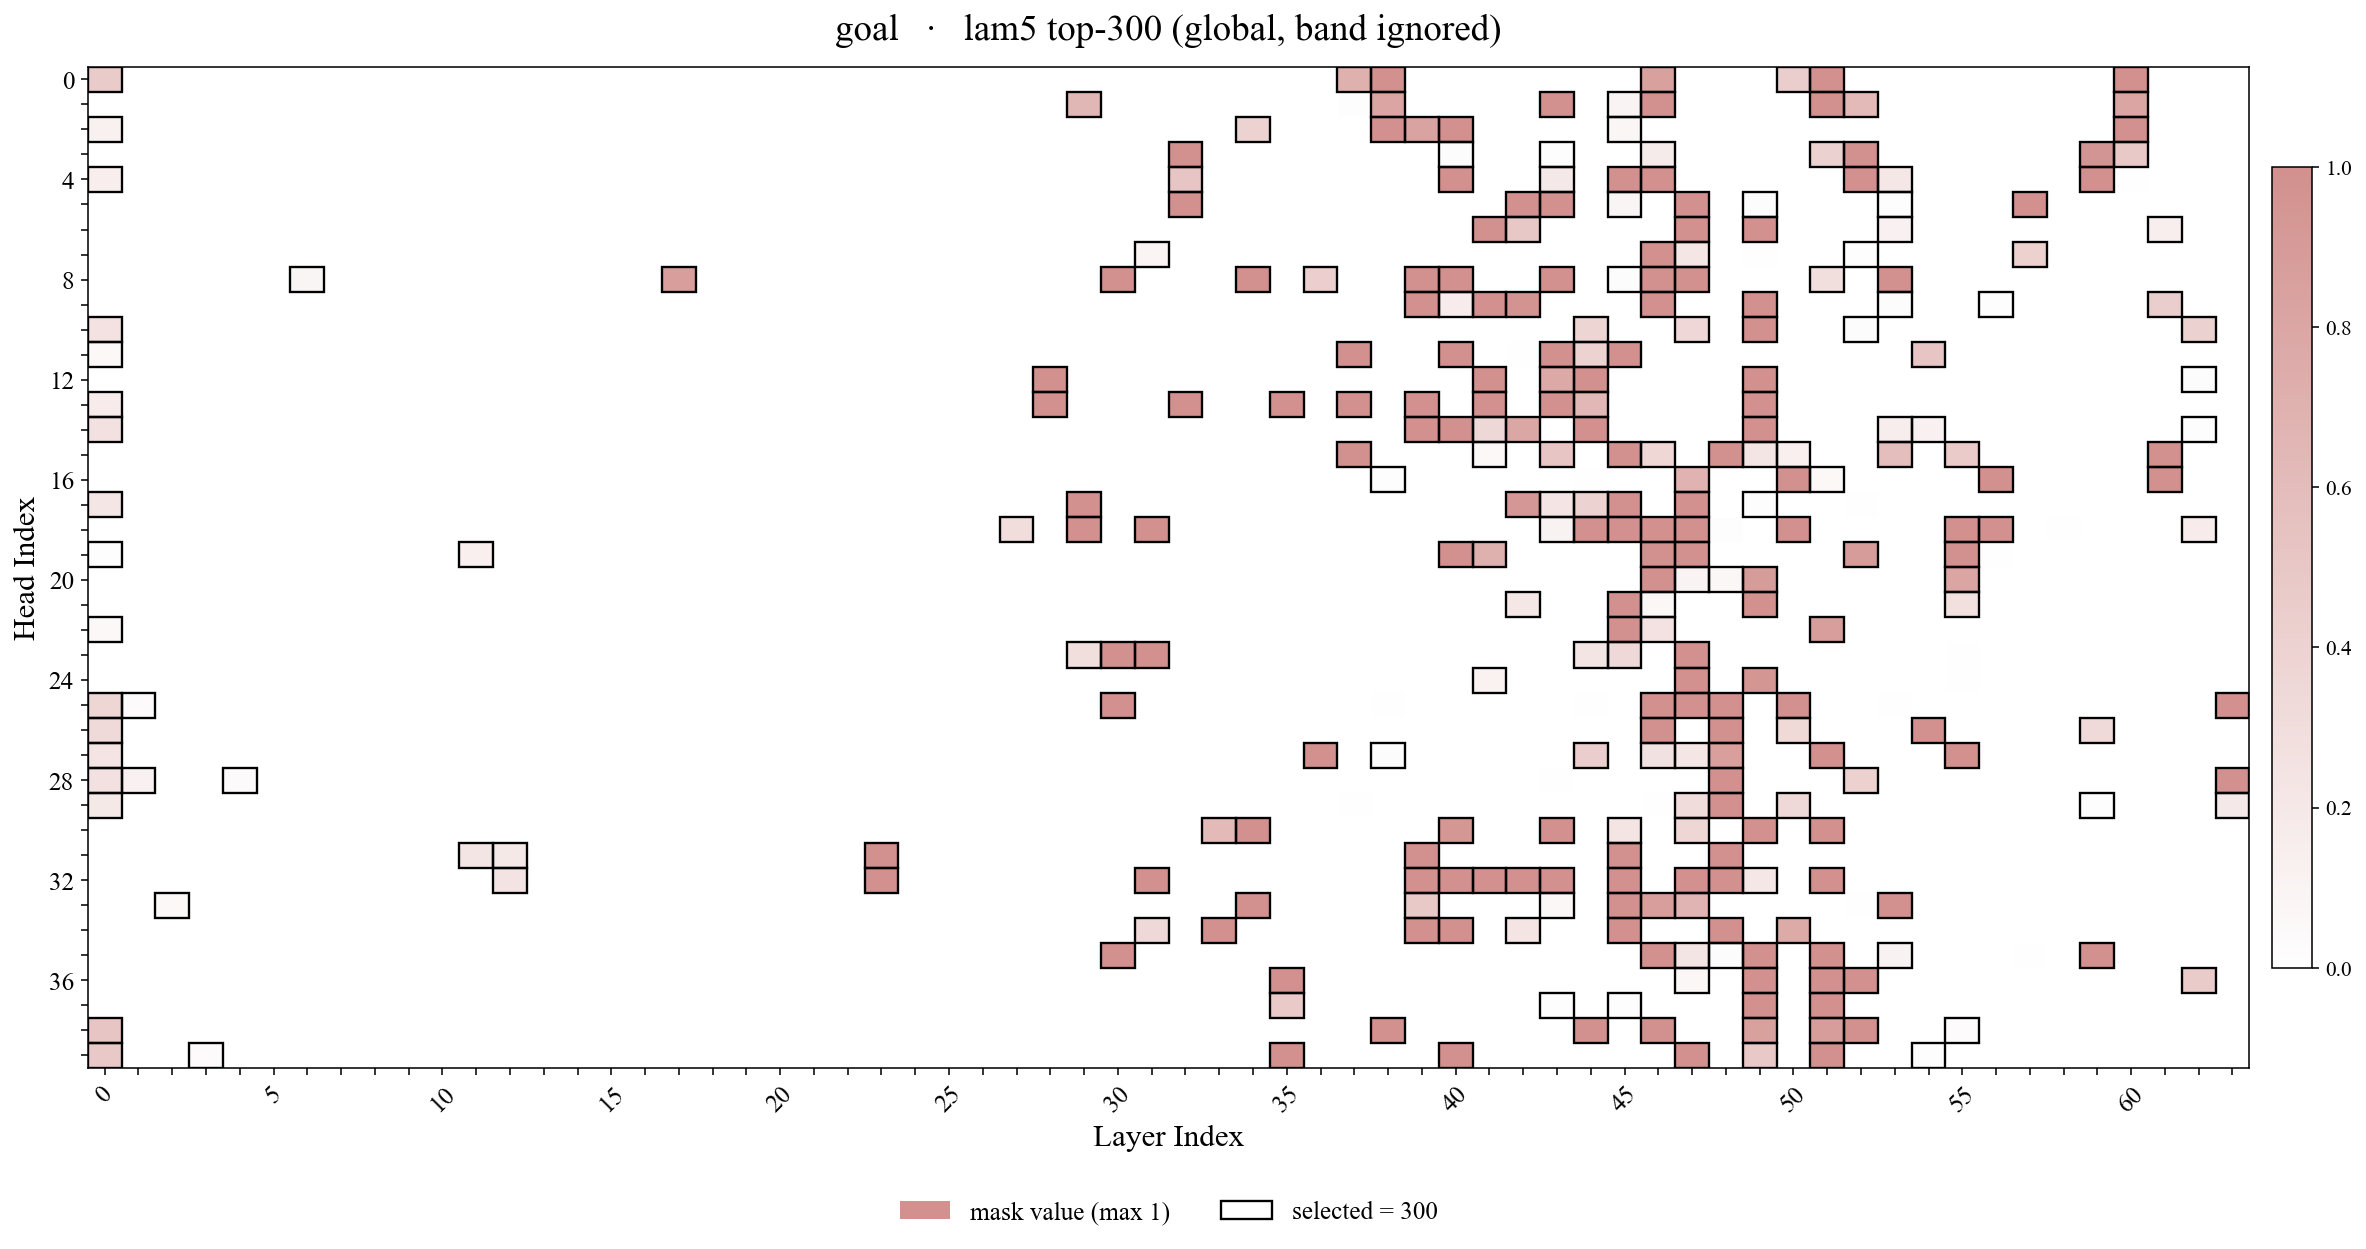

sparsity sweep · Qwen2.5-Coder-32B-Instruct                                           
                                                                                      
 name           n_sel   n_nz   s@1       s@K   tied@K   layers   top layers           
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 goal top-300     300    341     1   0.00851        1     0-63   L47:21 L46:19 L49:19

* tied@K > 1: the cut falls inside a tie block, so which heads land inside is index order, not importance.  !! also
s@K == 0: k has run past every scored head and is padding the selection with zero-score ones.

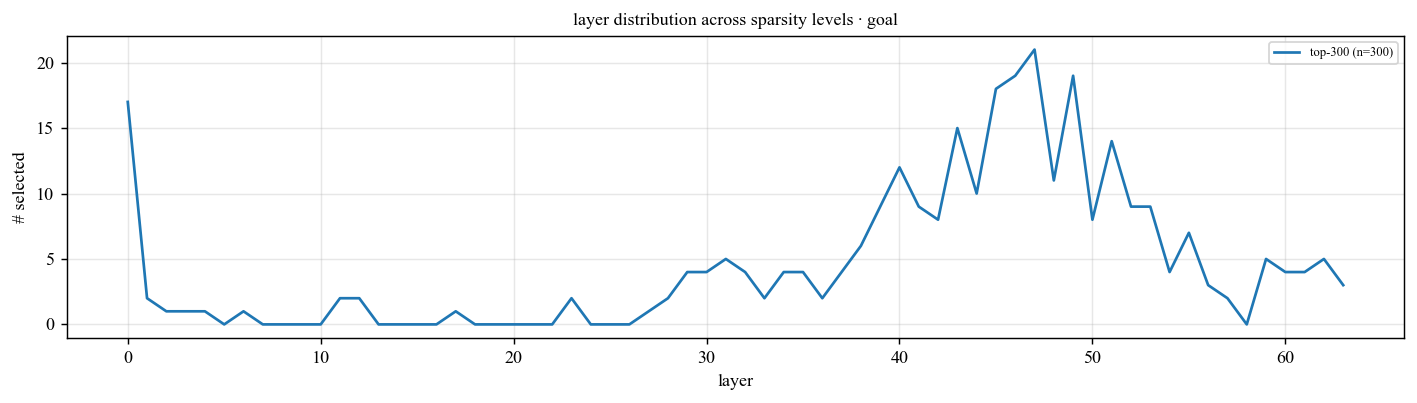

written

 300 heads -> 
/disk/u/arnab/Codes/Projects/goals/head_sets/Qwen2.5-Coder-32B-Instruct/goal_topk/goal__lam5_top300.json

use with:  python -m scripts.evaluation.eval_goalscope --heads <path>.json --strategy additive_norm --alpha <a>

In [21]:
# ── the sweep: load / inspect / export at each sparsity level ───────────────
SWEEP_SETS   = ["goal"]                      # e.g. ["goal", "gaze", "fv", "decision"]
SWEEP_TOPK   = [300]
SHOW_FIGURES = True                         # True -> one score-landscape figure per (set, k)
SAVE_JSON    = True
EXPORT_DIR   = Path(os.path.dirname(RES)) / "head_sets" / SLUG / "goal_topk"   # repo root: results/ is gitignored

def sweep_cfg(name, k):
    """SWEEP_CFG[name] at top-k. Falls back to CFG only if the set is absent from SWEEP_CFG, and
    says so — a silent fallback to a different lambda is exactly what this split exists to stop."""
    key = CFG_KEY.get(name, name)
    if key in SWEEP_CFG:
        c = dict(SWEEP_CFG[key])
    else:
        rich_print(f"[yellow]{name}: not in SWEEP_CFG — falling back to CFG[{key!r}][/yellow]")
        c = dict(CFG[key])
    c["topk"] = int(k)
    if key in ("goal", "decision"):
        c["threshold"] = None                # exactly one rule (validate_cfg enforces it)
    if key == "goal":
        c["band"] = None                     # top-k ranks globally, by design
    return c

sweep_rows, sweep_hs, written = [], [], []
for name in SWEEP_SETS:
    for k in SWEEP_TOPK:
        hs = load_set(name, sweep_cfg(name, k))
        if len(hs.selected) != k:
            rich_print(f"[yellow]{name} top-{k}: got {len(hs.selected)} heads "
                       f"(scored grid has only {int(np.isfinite(hs.grid).sum())})[/yellow]")
        # A top-k above the number of NON-ZERO scores is not a sparsity level: the tail is padded
        # with score-0 heads picked by index order (which is why layer 0 shows up wholesale).
        _nz = int((hs.grid[np.isfinite(hs.grid)] != 0).sum())
        if k > _nz:
            rich_print(f"[red]{name} top-{k}: only {_nz} heads have a NON-ZERO score, so "
                       f"{k - _nz} of the selected heads scored exactly 0 and were taken in index "
                       f"order. Cap the sweep at {_nz}.[/red]")
        sweep_rows.append(dict(head_stats(hs), name=f"{name} top-{k}"))
        sweep_hs.append((f"top-{k}", hs))
        if SHOW_FIGURES:
            plot_head_set(hs, name)
        if SAVE_JSON:
            p = head_set_path(hs, EXPORT_DIR)
            p.parent.mkdir(parents=True, exist_ok=True)
            p.write_text(json.dumps([[int(l), int(h)] for l, h in sorted(hs.selected)]))
            written.append(p)

stats_table(sweep_rows, f"sparsity sweep · {SLUG}")
layer_hist(sweep_hs, f"layer distribution across sparsity levels · {', '.join(SWEEP_SETS)}")

if written:
    rich_print("\n[bold]written[/bold]")
    for p in written:
        rich_print(f"  [green]{len(json.loads(p.read_text())):4d}[/green] heads -> {p}")
    rich_print("\n[grey58]use with:  python -m scripts.evaluation.eval_goalscope "
               "--heads <path>.json --strategy additive_norm --alpha <a>[/grey58]")